### Part A - Image Representation

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import zipfile
from pathlib import Path
from PIL import Image
from io import BytesIO
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
np.random.seed(42)  

folder = Path.cwd()
zip_files = list(folder.glob("*.zip"))

print("Current folder:", folder)
print("Zip files found:", [file.name for file in zip_files])

if len(zip_files) != 1:
    raise ValueError("Please keep exactly one dataset ZIP file in this folder.")

zip_path = zip_files[0]

with zipfile.ZipFile(zip_path, "r") as z:
    image_files = sorted([
        name for name in z.namelist()
        if name.lower().endswith((".pgm", ".png", ".jpg", ".jpeg"))
        and not Path(name).name.startswith("._")
        and "__MACOSX" not in name
    ])

print("Total images found:", len(image_files))
print("Sample image paths:", image_files[:10])

Current folder: c:\Users\choks\OneDrive\Desktop\DAU\Sem-1\Machine Learning Lab\202618035_HetChokshi_DS605\202618035_lab_7
Zip files found: ['archive (3).zip']
Total images found: 400
Sample image paths: ['s1/1.pgm', 's1/10.pgm', 's1/2.pgm', 's1/3.pgm', 's1/4.pgm', 's1/5.pgm', 's1/6.pgm', 's1/7.pgm', 's1/8.pgm', 's1/9.pgm']


#### Loading images and creating labels

In [ ]:
images = []
labels = []

with zipfile.ZipFile(zip_path, "r") as z:
    for file in image_files:
        parts = Path(file).parts
        subject = next(
            (p for p in parts if p.startswith("s") and p[1:].isdigit()),
            None
        )

        if subject is None:
            continue

        with z.open(file) as f:
            img = Image.open(BytesIO(f.read())).convert("L")
            img_array = np.array(img, dtype=np.float64)

        images.append(img_array)
        labels.append(int(subject[1:]))

images = np.array(images)
labels = np.array(labels)

print("Image shape:", images.shape)
print("Labels shape:",labels.shape)
print("Unique subjects:", len(np.unique(labels)))
print("Pixel intensity range:", images.min(), "to", images.max())

Image shape: (400, 112, 92)
Labels shape: (400,)
Unique subjects: 40
Pixel intensity range: 0.0 to 251.0


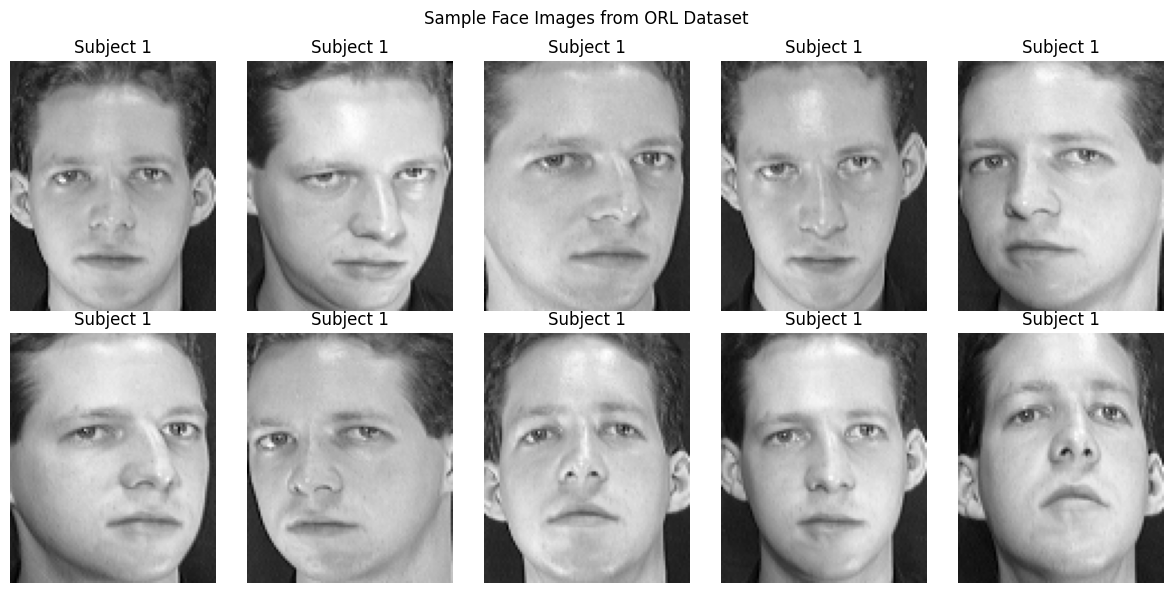

In [ ]:

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i], cmap="gray")
    ax.set_title(f"Subject {labels[i]}")
    ax.axis("off")

plt.suptitle("Sample Face Images from ORL Dataset")
plt.tight_layout()
plt.show()


#### Flattening the images

In [ ]:

n_samples, height, width = images.shape

X = images.reshape(n_samples, height * width)
y = labels

print("Original image shape:", images.shape)
print("Flattened feature matrix:", X.shape)
print("Labels shape:", y.shape)


Original image shape: (400, 112, 92)
Flattened feature matrix: (400, 10304)
Labels shape: (400,)


#### Train Test Split

In [ ]:
X_train,X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training subjects:", len(np.unique(y_train)))
print("Testing subjects:", len(np.unique(y_test)))

assert set(np.unique(y_train)) == set(np.unique(y_test))


Training data: (320, 10304)
Testing data: (80, 10304)
Training subjects: 40
Testing subjects: 40


### Part B - PCA, Eigenfaces and Compression

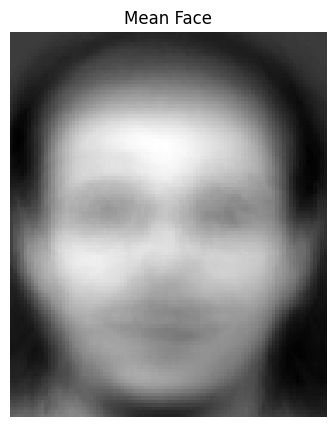

Mean face shape: (10304,)
Centered training data: (320, 10304)


In [ ]:
mean_face = np.mean(X_train, axis=0)

X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

plt.figure(figsize=(5, 5))
plt.imshow(mean_face.reshape(height, width), cmap="gray")
plt.title("Mean Face")
plt.axis("off")
plt.show()

print("Mean face shape:", mean_face.shape)
print("Centered training data:", X_train_centered.shape)

In [ ]:

n_train = X_train_centered.shape[0]

small_cov = (
    X_train_centered @ X_train_centered.T
) / (n_train - 1)

eigenvalues, small_eigenvectors = np.linalg.eigh(small_cov)

indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[indices]
small_eigenvectors = small_eigenvectors[:, indices]

valid = eigenvalues > 1e-8

eigenvalues = eigenvalues[valid]
small_eigenvectors = small_eigenvectors[:, valid]

principal_components = (
    X_train_centered.T @ small_eigenvectors
)

principal_components /= np.sqrt(
    (n_train - 1) * eigenvalues
)

principal_components = principal_components.T

print("Principal components shape:", principal_components.shape)
print("Eigenvalues shape:", eigenvalues.shape)


Principal components shape: (319, 10304)
Eigenvalues shape: (319,)


#### Implementing PCA using SVD

In [ ]:

U, S, Vt = np.linalg.svd(
    X_train_centered,
    full_matrices=False
)

svd_eigenvalues = (S ** 2) / (n_train - 1)

svd_components = Vt

print("SVD components shape:", svd_components.shape)

print(
    "Eigenvalues match:",
    np.allclose(
        eigenvalues,
        svd_eigenvalues[:len(eigenvalues)],
        rtol=1e-5,
        atol=1e-5
    )
)


SVD components shape: (320, 10304)
Eigenvalues match: True


Components required for 90% variance: 98


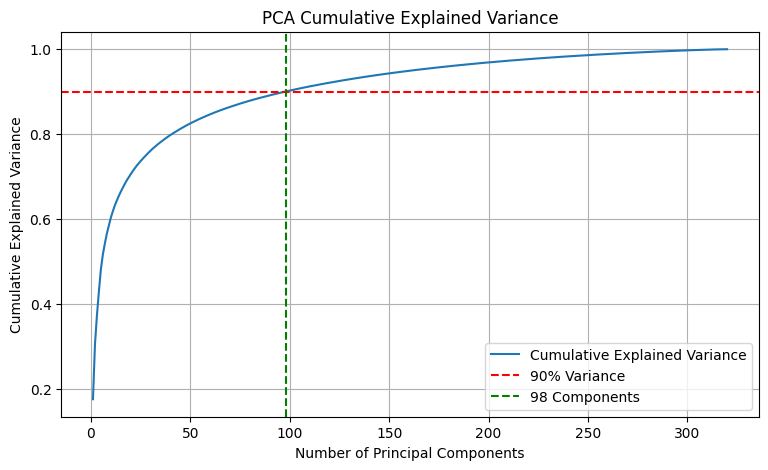

In [ ]:

explained_variance_ratio = (
    svd_eigenvalues / np.sum(svd_eigenvalues)
)

cumulative_variance = np.cumsum(explained_variance_ratio)

k_90 = np.searchsorted(cumulative_variance, 0.90) + 1

print("Components required for 90% variance:", k_90)

plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance,
    label="Cumulative Explained Variance"
)

plt.axhline(0.90, color="red", linestyle="--", label="90% Variance")
plt.axvline(k_90, color="green", linestyle="--", label=f"{k_90} Components")

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")
plt.legend()
plt.grid(True)
plt.show()


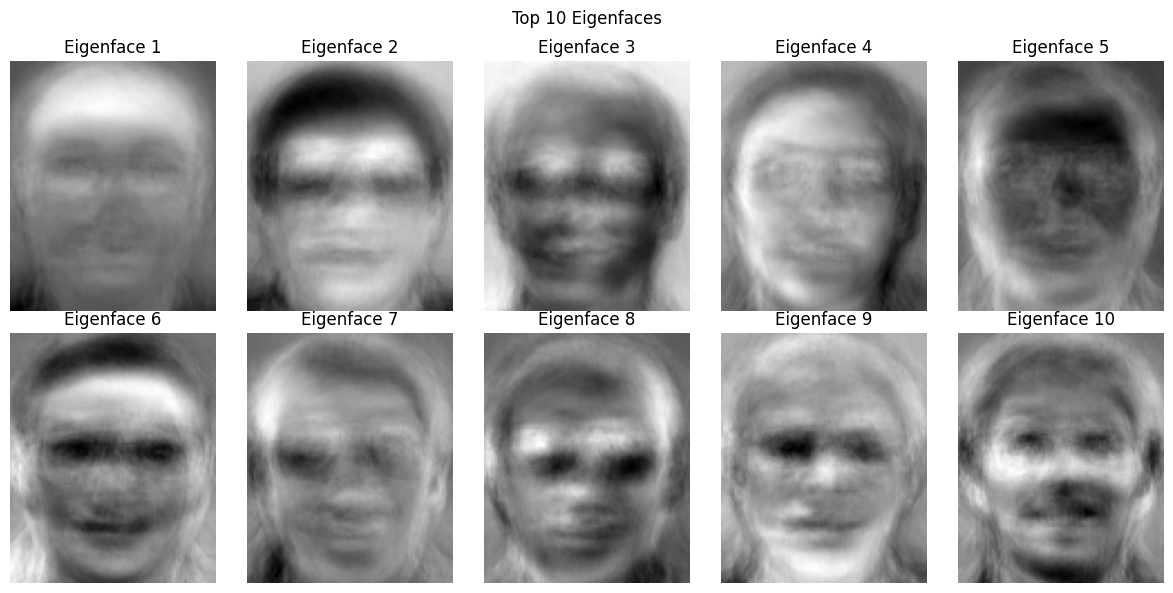

In [ ]:

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    eigenface = svd_components[i].reshape(height, width)

    ax.imshow(eigenface, cmap="gray")
    ax.set_title(f"Eigenface {i + 1}")
    ax.axis("off")

plt.suptitle("Top 10 Eigenfaces")
plt.tight_layout()
plt.show()


In [ ]:

components_90 = svd_components[:k_90]

X_train_pca = X_train_centered @ components_90.T
X_test_pca = X_test_centered @ components_90.T

print("Original training shape:", X_train.shape)
print("Reduced training shape:", X_train_pca.shape)

print("Original testing shape:", X_test.shape)
print("Reduced testing shape:", X_test_pca.shape)


Original training shape: (320, 10304)
Reduced training shape: (320, 98)
Original testing shape: (80, 10304)
Reduced testing shape: (80, 98)


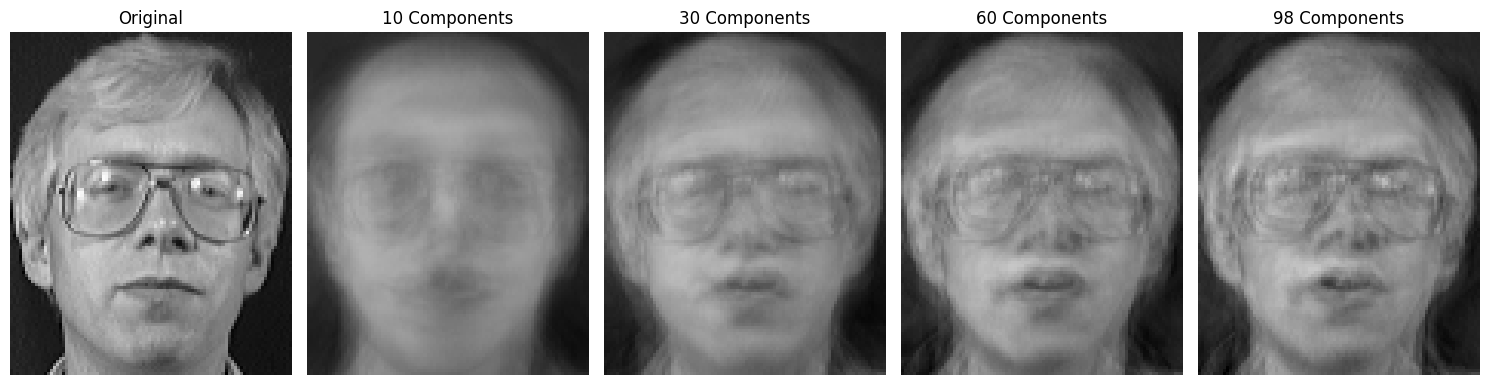

In [ ]:

component_counts = sorted(set(
    [10, 30, 60, k_90]
))

sample = X_test[0]
sample_centered = sample - mean_face

fig, axes = plt.subplots(
    1,
    len(component_counts) + 1,
    figsize=(15, 4)
)

axes[0].imshow(sample.reshape(height, width), cmap="gray")
axes[0].set_title("Original")
axes[0].axis("off")

for i, k in enumerate(component_counts):
    components = svd_components[:k]

    projected = sample_centered @ components.T
    reconstructed = projected @ components + mean_face

    axes[i + 1].imshow(
        reconstructed.reshape(height, width),
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axes[i + 1].set_title(f"{k} Components")
    axes[i + 1].axis("off")

plt.tight_layout()
plt.show()


In [ ]:

results = []

for k in component_counts:
    components = svd_components[:k]

    projected = X_test_centered @ components.T
    reconstructed = projected @ components + mean_face

    mse = np.mean((X_test - reconstructed) ** 2)

    results.append({
        "Components": k,
        "Explained Variance (%)": round(
            cumulative_variance[k - 1] * 100, 2
        ),
        "Reconstruction MSE": round(mse, 2)
    })

reconstruction_df = pd.DataFrame(results)

display(reconstruction_df)


,Components,Explained Variance (%),Reconstruction MSE
0,10,60.40,664.88
1,30,76.16,474.28
2,60,84.70,380.93
3,98,90.06,334.99


In [ ]:

original_values = X_train.size

compressed_values = (
    X_train_pca.size
    + components_90.size
    + mean_face.size
)

storage_reduction = (
    1 - compressed_values / original_values
) * 100

print("Original stored values:", original_values)
print("PCA stored values:", compressed_values)
print(f"Storage reduction: {storage_reduction:.2f}%")


Original stored values: 3297280
PCA stored values: 1051456
Storage reduction: 68.11%


### Part C - Recognition in PCA Space

#### Implementing Euclidean distance matching

In [ ]:

def nearest_neighbor_predict(X_train_features, X_test_features, y_train):
    distances = np.sum(
        (X_test_features[:, None, :] - X_train_features[None, :, :]) ** 2,
        axis=2
    )

    nearest_indices = np.argmin(distances, axis=1)

    predictions = y_train[nearest_indices]

    return predictions, nearest_indices, distances


y_pred_pca, nearest_indices_pca, distances_pca = nearest_neighbor_predict(
    X_train_pca,
    X_test_pca,
    y_train
)

print("PCA predictions shape:", y_pred_pca.shape)
print("First 10 predicted labels:", y_pred_pca[:10])
print("First 10 actual labels:", y_test[:10])


PCA predictions shape: (80,)
First 10 predicted labels: [ 2 36 19 17 40 24 33 20  4 35]
First 10 actual labels: [ 2 36 19 17 40 24 33 20  4 35]


#### Calculating PCA recognition accuracy

In [ ]:

pca_accuracy = accuracy_score(y_test, y_pred_pca)

print(f"PCA Recognition Accuracy: {pca_accuracy * 100:.2f}%")
print("Correct predictions:", np.sum(y_test == y_pred_pca))
print("Incorrect predictions:", np.sum(y_test != y_pred_pca))


PCA Recognition Accuracy: 96.25%
Correct predictions: 77
Incorrect predictions: 3


#### Performing face recognition using raw pixels

In [ ]:

y_pred_raw, nearest_indices_raw, distances_raw = nearest_neighbor_predict(
    X_train,
    X_test,
    y_train
)

raw_accuracy = accuracy_score(y_test, y_pred_raw)

print(f"Raw Pixel Recognition Accuracy: {raw_accuracy * 100:.2f}%")
print(f"PCA Recognition Accuracy: {pca_accuracy * 100:.2f}%")


Raw Pixel Recognition Accuracy: 96.25%
PCA Recognition Accuracy: 96.25%


#### Comparing recognition accuracy

,Method,Features,Accuracy (%)
0,Raw Pixels,10304,96.25
1,PCA Features,98,96.25


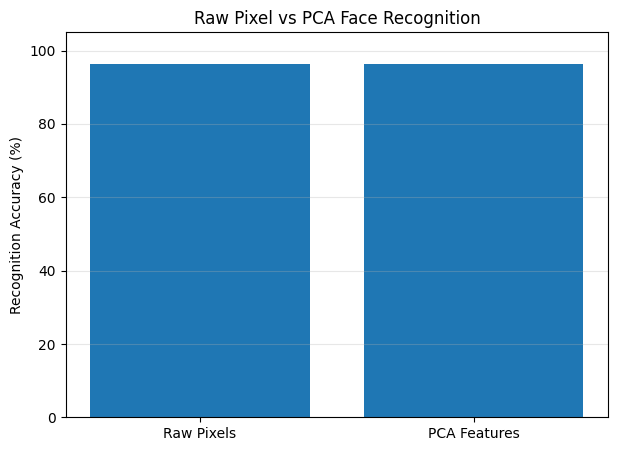

In [ ]:

comparison_df = pd.DataFrame({
    "Method": ["Raw Pixels", "PCA Features"],
    "Features": [X_train.shape[1], X_train_pca.shape[1]],
    "Accuracy (%)": [raw_accuracy * 100, pca_accuracy * 100]
})

display(comparison_df)

plt.figure(figsize=(7, 5))
plt.bar(
    comparison_df["Method"],
    comparison_df["Accuracy (%)"]
)

plt.ylabel("Recognition Accuracy (%)")
plt.title("Raw Pixel vs PCA Face Recognition")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)
plt.show()


#### Visualizing correct and incorrect face matches

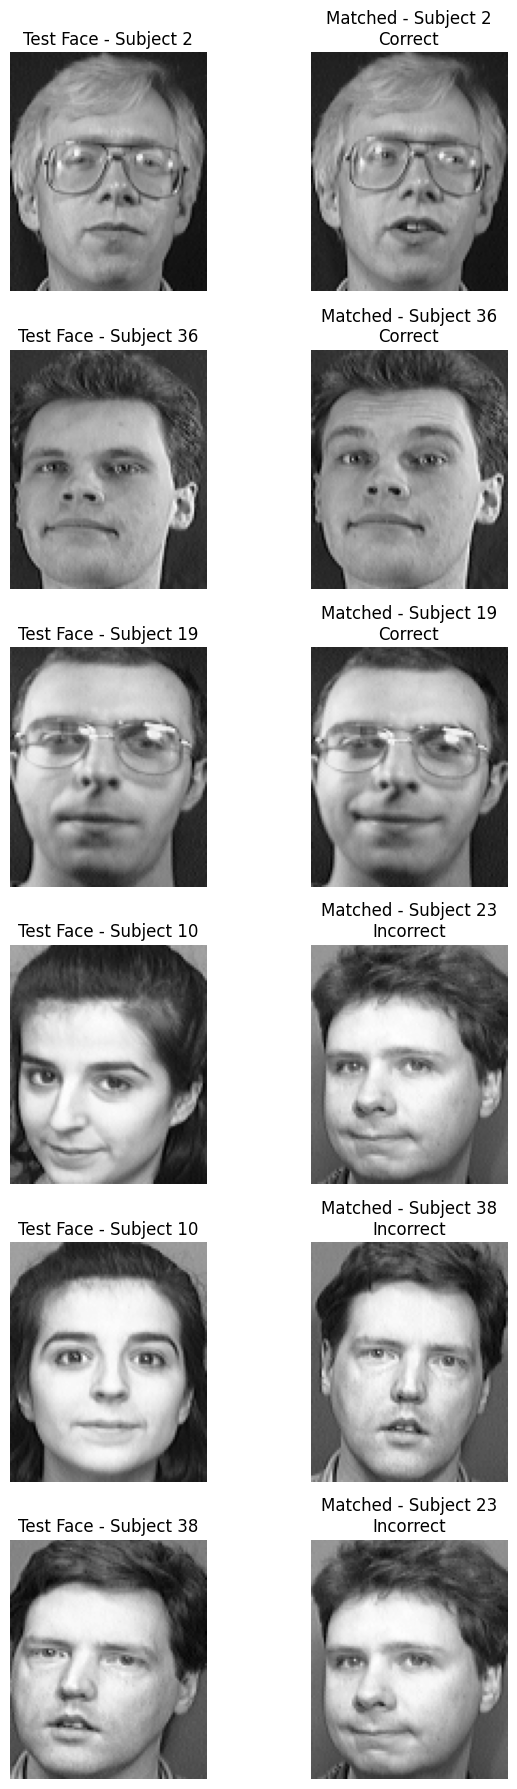

In [ ]:

correct_indices = np.where(y_pred_pca == y_test)[0]
incorrect_indices = np.where(y_pred_pca != y_test)[0]

selected_correct = correct_indices[:3]
selected_incorrect = incorrect_indices[:3]

selected_indices = np.concatenate([
    selected_correct,
    selected_incorrect
])

fig, axes = plt.subplots(
    len(selected_indices),
    2,
    figsize=(7, 3 * len(selected_indices)),
    squeeze=False
)

for row, idx in enumerate(selected_indices):
    test_face = X_test[idx].reshape(height, width)

    matched_face = X_train[
        nearest_indices_pca[idx]
    ].reshape(height, width)

    is_correct = y_pred_pca[idx] == y_test[idx]

    axes[row, 0].imshow(test_face, cmap="gray")
    axes[row, 0].set_title(f"Test Face - Subject {y_test[idx]}")

    axes[row, 1].imshow(matched_face, cmap="gray")
    axes[row, 1].set_title(
        f"Matched - Subject {y_pred_pca[idx]}\n"
        f"{'Correct' if is_correct else 'Incorrect'}"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()


#### Comparing recognition using different PCA dimentions

,Components,Accuracy (%)
0,10,95.00
1,20,96.25
2,30,96.25
3,50,98.75
4,60,97.50
5,80,97.50
6,98,96.25
7,120,96.25
8,150,96.25


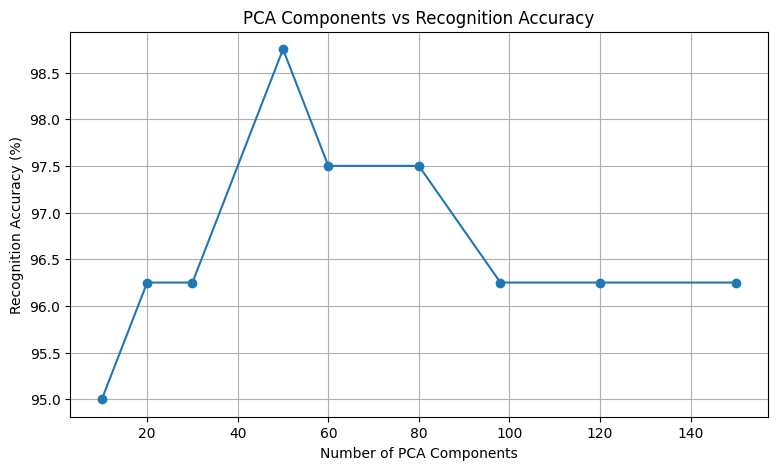

In [ ]:

component_options = [10, 20, 30, 50, 60, 80, 98, 120, 150]

accuracy_results = []

for k in component_options:
    components = svd_components[:k]

    train_features = X_train_centered @ components.T
    test_features = X_test_centered @ components.T

    predictions, _, _ = nearest_neighbor_predict(
        train_features,
        test_features,
        y_train
    )

    accuracy_results.append({
        "Components": k,
        "Accuracy (%)": accuracy_score(y_test, predictions) * 100
    })

accuracy_df = pd.DataFrame(accuracy_results)

display(accuracy_df)

plt.figure(figsize=(9, 5))
plt.plot(
    accuracy_df["Components"],
    accuracy_df["Accuracy (%)"],
    marker="o"
)

plt.xlabel("Number of PCA Components")
plt.ylabel("Recognition Accuracy (%)")
plt.title("PCA Components vs Recognition Accuracy")
plt.grid(True)
plt.show()


### Part D - Traditional Machine Learning

In [ ]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
import time


In [ ]:

models = {
    "KNN": KNeighborsClassifier(n_neighbors=1),
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=3000))
    ]),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="rbf"))
    ])
}

model_results = []
trained_models = {}

for name, model in models.items():
    start = time.time()

    model.fit(X_train_pca, y_train)

    training_time = time.time() - start

    predictions = model.predict(X_test_pca)

    accuracy = accuracy_score(y_test, predictions)

    trained_models[name] = model

    model_results.append({
        "Model": name,
        "Accuracy (%)": accuracy * 100,
        "Training Time (s)": training_time
    })

model_results_df = pd.DataFrame(model_results)

display(model_results_df)


,Model,Accuracy (%),Training Time (s)
0,KNN,96.25,0.011961
1,Logistic Regression,93.75,0.055517
2,SVM,98.75,0.024267


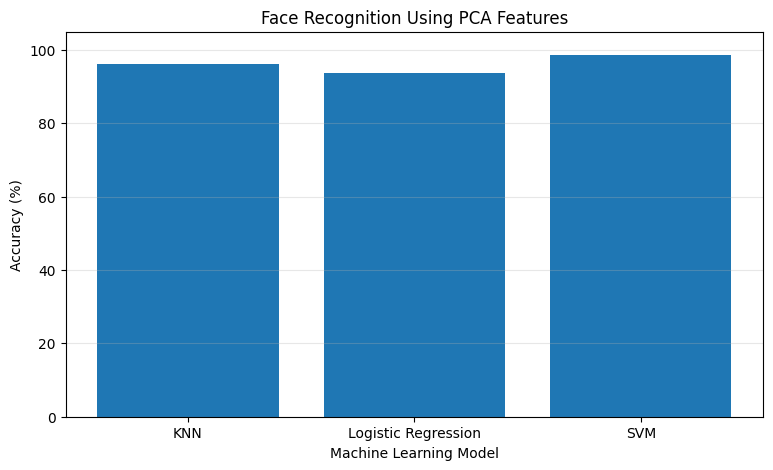

In [ ]:

plt.figure(figsize=(9, 5))

plt.bar(
    model_results_df["Model"],
    model_results_df["Accuracy (%)"]
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.title("Face Recognition Using PCA Features")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)

plt.show()


In [ ]:

cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

param_grids = {
    "KNN": {
        "n_neighbors": [1, 3, 5, 7],
        "weights": ["uniform", "distance"]
    },
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10, 100]
    },
    "SVM": {
        "classifier__C": [0.1, 1, 10, 100],
        "classifier__gamma": ["scale", 0.001, 0.01]
    }
}

best_models = {}
tuning_results = []

for name, model in models.items():
    search = GridSearchCV(
        model,
        param_grids[name],
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    search.fit(X_train_pca, y_train)

    best_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best Parameters": search.best_params_,
        "CV Accuracy (%)": search.best_score_ * 100
    })

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df)


,Model,Best Parameters,CV Accuracy (%)
0,KNN,"{'n_neighbors': 1, 'weights': 'uniform'}",95.9375
1,Logistic Regression,{'classifier__C': 1},92.5000
2,SVM,"{'classifier__C': 10, 'classifier__gamma': 0.001}",91.8750


In [ ]:

final_results = []

for name, model in best_models.items():
    predictions = model.predict(X_test_pca)

    accuracy = accuracy_score(y_test, predictions)

    final_results.append({
        "Model": name,
        "Test Accuracy (%)": accuracy * 100
    })

final_results_df = pd.DataFrame(final_results)

display(final_results_df)


,Model,Test Accuracy (%)
0,KNN,96.25
1,Logistic Regression,93.75
2,SVM,95.00


,Model,Baseline Accuracy (%),Tuned Accuracy (%)
0,KNN,96.25,96.25
1,Logistic Regression,93.75,93.75
2,SVM,98.75,95.00


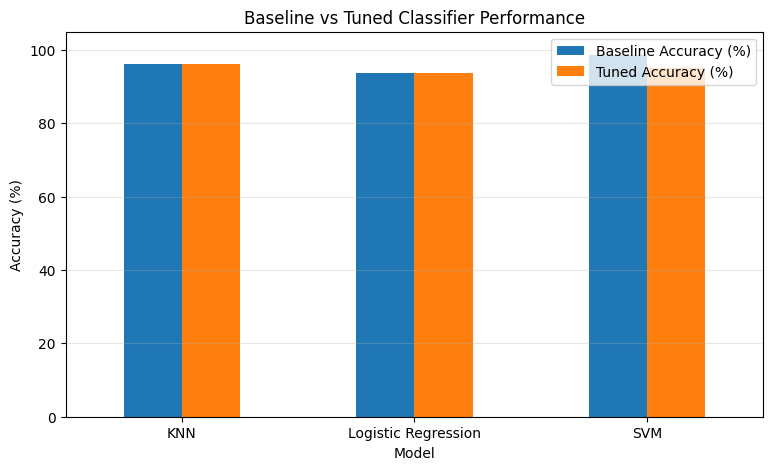

In [ ]:

comparison = model_results_df[
    ["Model", "Accuracy (%)"]
].merge(
    final_results_df,
    on="Model"
)

comparison.columns = [
    "Model",
    "Baseline Accuracy (%)",
    "Tuned Accuracy (%)"
]

display(comparison)

comparison.set_index("Model").plot(
    kind="bar",
    figsize=(9, 5)
)

plt.ylabel("Accuracy (%)")
plt.title("Baseline vs Tuned Classifier Performance")
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()


In [ ]:

for name, model in best_models.items():
    predictions = model.predict(X_test_pca)

    print(f"\n{name} Classification Report")
    print(
        classification_report(
            y_test,
            predictions,
            zero_division=0
        )
    )



KNN Classification Report
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         2
           2       1.00      1.00      1.00         2
           3       1.00      1.00      1.00         2
           4       1.00      1.00      1.00         2
           5       1.00      1.00      1.00         2
           6       1.00      1.00      1.00         2
           7       1.00      1.00      1.00         2
           8       1.00      1.00      1.00         2
           9       1.00      1.00      1.00         2
          10       0.00      0.00      0.00         2
          11       1.00      1.00      1.00         2
          12       1.00      1.00      1.00         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         2
          15       1.00      1.00      1.00         2
          16       1.00      1.00      1.00         2
          17       1.00      1.00      1.00         2


In [ ]:

from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

comparison.to_csv(output_dir / "model_comparison.csv", index=False)
accuracy_df.to_csv(output_dir / "pca_accuracy_comparison.csv", index=False)
reconstruction_df.to_csv(output_dir / "reconstruction_results.csv", index=False)

print("Results saved successfully!")


Results saved successfully!


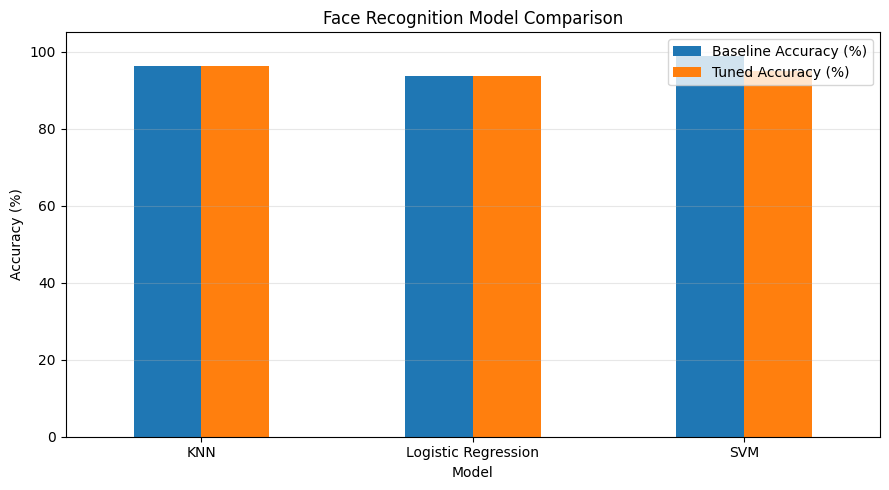

In [ ]:

ax = comparison.set_index("Model").plot(
    kind="bar",
    figsize=(9, 5)
)

plt.ylabel("Accuracy (%)")
plt.title("Face Recognition Model Comparison")
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    output_dir / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

print("DS605 LAB ASSIGNMENT 7 - FINAL SUMMARY")
print("-" * 45)

print("Dataset: AT&T ORL Face Dataset")
print("Total Images:", len(images))
print("Total Subjects:", len(np.unique(labels)))

print("Training Images:", len(X_train))
print("Testing Images:", len(X_test))

print("Original Features:", X_train.shape[1])
print("PCA Components:", k_90)

print(f"Explained Variance: {cumulative_variance[k_90-1]*100:.2f}%")

print(f"Raw Pixel Recognition: {raw_accuracy*100:.2f}%")
print(f"PCA Recognition: {pca_accuracy*100:.2f}%")

print("\nMachine Learning Results:")
print(comparison.to_string(index=False))

best_baseline = model_results_df.loc[
    model_results_df["Accuracy (%)"].idxmax()
]

print("\nBest Baseline Model:", best_baseline["Model"])
print(f"Best Baseline Accuracy: {best_baseline['Accuracy (%)']:.2f}%")


DS605 LAB ASSIGNMENT 7 - FINAL SUMMARY
---------------------------------------------
Dataset: AT&T ORL Face Dataset
Total Images: 400
Total Subjects: 40
Training Images: 320
Testing Images: 80
Original Features: 10304
PCA Components: 98
Explained Variance: 90.06%
Raw Pixel Recognition: 96.25%
PCA Recognition: 96.25%

Machine Learning Results:
              Model  Baseline Accuracy (%)  Tuned Accuracy (%)
                KNN                  96.25               96.25
Logistic Regression                  93.75               93.75
                SVM                  98.75               95.00

Best Baseline Model: SVM
Best Baseline Accuracy: 98.75%


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import zipfile
from pathlib import Path
from PIL import Image
from io import BytesIO
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
np.random.seed(42)  

folder = Path.cwd()
zip_files = list(folder.glob("*.zip"))

print("Current folder:", folder)
print("Zip files found:", [file.name for file in zip_files])

if len(zip_files) != 1:
    raise ValueError("Please keep exactly one dataset ZIP file in this folder.")

zip_path = zip_files[0]

with zipfile.ZipFile(zip_path, "r") as z:
    image_files = sorted([
        name for name in z.namelist()
        if name.lower().endswith((".pgm", ".png", ".jpg", ".jpeg"))
        and not Path(name).name.startswith("._")
        and "__MACOSX" not in name
    ])

print("Total images found:", len(image_files))
print("Sample image paths:", image_files[:10])

Current folder: c:\Users\daksh\OneDrive\Documents\DAU\SEM 1\Machine Learning\202618033_DS605\202618033_Lab_7
Zip files found: []


ValueError: Please keep exactly one dataset ZIP file in this folder.

#### Loading images and creating labels

In [ ]:
images = []
labels = []

with zipfile.ZipFile(zip_path, "r") as z:
    for file in image_files:
        parts = Path(file).parts
        subject = next(
            (p for p in parts if p.startswith("s") and p[1:].isdigit()),
            None
        )

        if subject is None:
            continue

        with z.open(file) as f:
            img = Image.open(BytesIO(f.read())).convert("L")
            img_array = np.array(img, dtype=np.float64)

        images.append(img_array)
        labels.append(int(subject[1:]))

images = np.array(images)
labels = np.array(labels)

print("Image shape:", images.shape)
print("Labels shape:",labels.shape)
print("Unique subjects:", len(np.unique(labels)))
print("Pixel intensity range:", images.min(), "to", images.max())

Image shape: (400, 112, 92)
Labels shape: (400,)
Unique subjects: 40
Pixel intensity range: 0.0 to 251.0


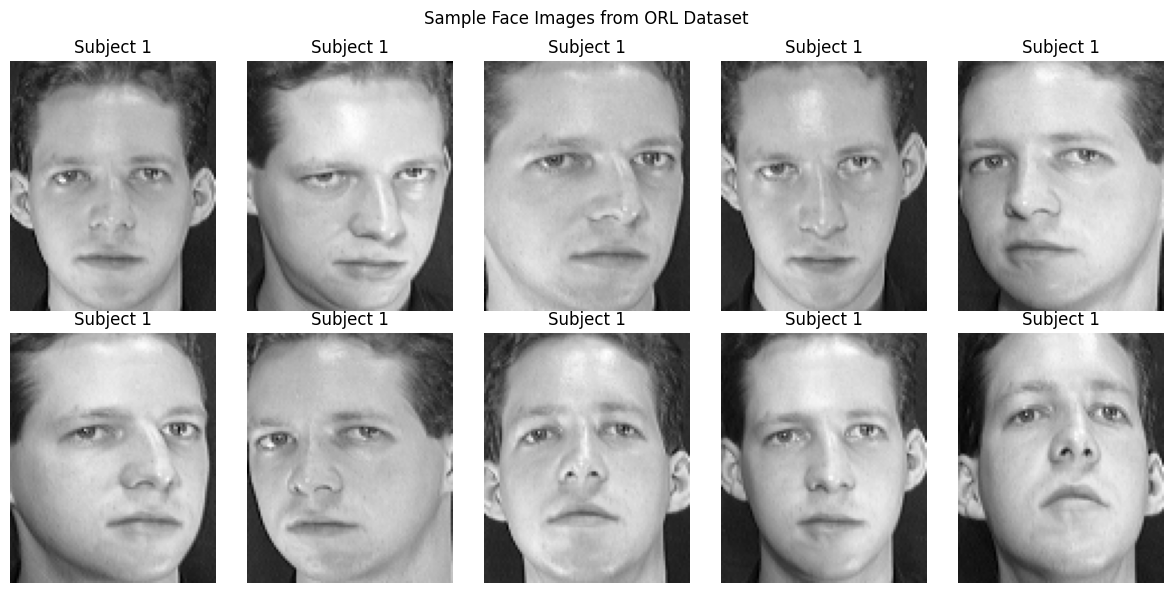

In [ ]:

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i], cmap="gray")
    ax.set_title(f"Subject {labels[i]}")
    ax.axis("off")

plt.suptitle("Sample Face Images from ORL Dataset")
plt.tight_layout()
plt.show()


#### Flattening the images

In [ ]:

n_samples, height, width = images.shape

X = images.reshape(n_samples, height * width)
y = labels

print("Original image shape:", images.shape)
print("Flattened feature matrix:", X.shape)
print("Labels shape:", y.shape)


Original image shape: (400, 112, 92)
Flattened feature matrix: (400, 10304)
Labels shape: (400,)


#### Train Test Split

In [ ]:
X_train,X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training subjects:", len(np.unique(y_train)))
print("Testing subjects:", len(np.unique(y_test)))

assert set(np.unique(y_train)) == set(np.unique(y_test))


Training data: (320, 10304)
Testing data: (80, 10304)
Training subjects: 40
Testing subjects: 40


### Part B - PCA, Eigenfaces and Compression

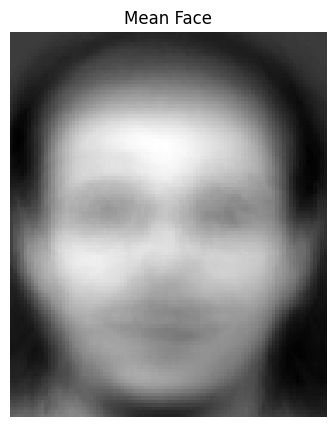

Mean face shape: (10304,)
Centered training data: (320, 10304)


In [ ]:
mean_face = np.mean(X_train, axis=0)

X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

plt.figure(figsize=(5, 5))
plt.imshow(mean_face.reshape(height, width), cmap="gray")
plt.title("Mean Face")
plt.axis("off")
plt.show()

print("Mean face shape:", mean_face.shape)
print("Centered training data:", X_train_centered.shape)

In [ ]:

n_train = X_train_centered.shape[0]

small_cov = (
    X_train_centered @ X_train_centered.T
) / (n_train - 1)

eigenvalues, small_eigenvectors = np.linalg.eigh(small_cov)

indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[indices]
small_eigenvectors = small_eigenvectors[:, indices]

valid = eigenvalues > 1e-8

eigenvalues = eigenvalues[valid]
small_eigenvectors = small_eigenvectors[:, valid]

principal_components = (
    X_train_centered.T @ small_eigenvectors
)

principal_components /= np.sqrt(
    (n_train - 1) * eigenvalues
)

principal_components = principal_components.T

print("Principal components shape:", principal_components.shape)
print("Eigenvalues shape:", eigenvalues.shape)


Principal components shape: (319, 10304)
Eigenvalues shape: (319,)


#### Implementing PCA using SVD

In [ ]:

U, S, Vt = np.linalg.svd(
    X_train_centered,
    full_matrices=False
)

svd_eigenvalues = (S ** 2) / (n_train - 1)

svd_components = Vt

print("SVD components shape:", svd_components.shape)

print(
    "Eigenvalues match:",
    np.allclose(
        eigenvalues,
        svd_eigenvalues[:len(eigenvalues)],
        rtol=1e-5,
        atol=1e-5
    )
)


SVD components shape: (320, 10304)
Eigenvalues match: True


Components required for 90% variance: 98


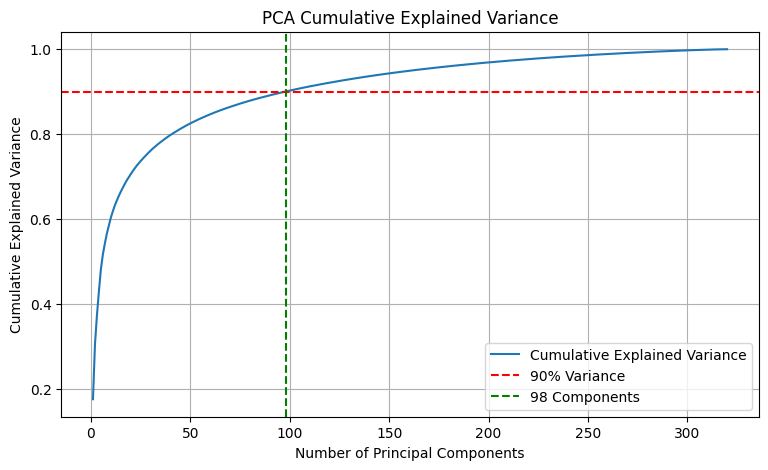

In [ ]:

explained_variance_ratio = (
    svd_eigenvalues / np.sum(svd_eigenvalues)
)

cumulative_variance = np.cumsum(explained_variance_ratio)

k_90 = np.searchsorted(cumulative_variance, 0.90) + 1

print("Components required for 90% variance:", k_90)

plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance,
    label="Cumulative Explained Variance"
)

plt.axhline(0.90, color="red", linestyle="--", label="90% Variance")
plt.axvline(k_90, color="green", linestyle="--", label=f"{k_90} Components")

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")
plt.legend()
plt.grid(True)
plt.show()


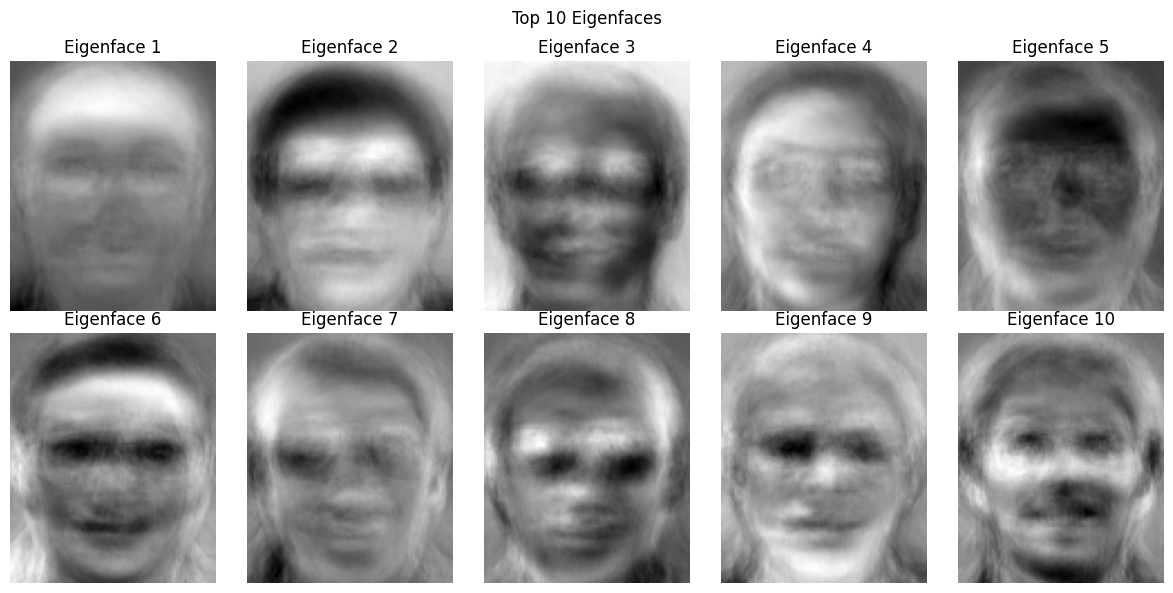

In [ ]:

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    eigenface = svd_components[i].reshape(height, width)

    ax.imshow(eigenface, cmap="gray")
    ax.set_title(f"Eigenface {i + 1}")
    ax.axis("off")

plt.suptitle("Top 10 Eigenfaces")
plt.tight_layout()
plt.show()


In [ ]:

components_90 = svd_components[:k_90]

X_train_pca = X_train_centered @ components_90.T
X_test_pca = X_test_centered @ components_90.T

print("Original training shape:", X_train.shape)
print("Reduced training shape:", X_train_pca.shape)

print("Original testing shape:", X_test.shape)
print("Reduced testing shape:", X_test_pca.shape)


Original training shape: (320, 10304)
Reduced training shape: (320, 98)
Original testing shape: (80, 10304)
Reduced testing shape: (80, 98)


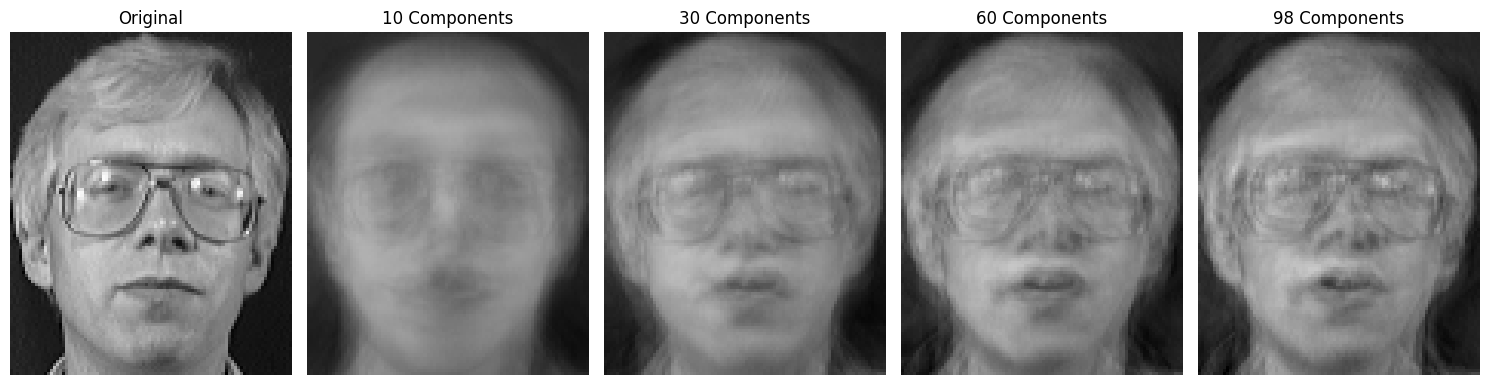

In [ ]:

component_counts = sorted(set(
    [10, 30, 60, k_90]
))

sample = X_test[0]
sample_centered = sample - mean_face

fig, axes = plt.subplots(
    1,
    len(component_counts) + 1,
    figsize=(15, 4)
)

axes[0].imshow(sample.reshape(height, width), cmap="gray")
axes[0].set_title("Original")
axes[0].axis("off")

for i, k in enumerate(component_counts):
    components = svd_components[:k]

    projected = sample_centered @ components.T
    reconstructed = projected @ components + mean_face

    axes[i + 1].imshow(
        reconstructed.reshape(height, width),
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axes[i + 1].set_title(f"{k} Components")
    axes[i + 1].axis("off")

plt.tight_layout()
plt.show()


In [ ]:

results = []

for k in component_counts:
    components = svd_components[:k]

    projected = X_test_centered @ components.T
    reconstructed = projected @ components + mean_face

    mse = np.mean((X_test - reconstructed) ** 2)

    results.append({
        "Components": k,
        "Explained Variance (%)": round(
            cumulative_variance[k - 1] * 100, 2
        ),
        "Reconstruction MSE": round(mse, 2)
    })

reconstruction_df = pd.DataFrame(results)

display(reconstruction_df)


,Components,Explained Variance (%),Reconstruction MSE
0,10,60.40,664.88
1,30,76.16,474.28
2,60,84.70,380.93
3,98,90.06,334.99


In [ ]:

original_values = X_train.size

compressed_values = (
    X_train_pca.size
    + components_90.size
    + mean_face.size
)

storage_reduction = (
    1 - compressed_values / original_values
) * 100

print("Original stored values:", original_values)
print("PCA stored values:", compressed_values)
print(f"Storage reduction: {storage_reduction:.2f}%")


Original stored values: 3297280
PCA stored values: 1051456
Storage reduction: 68.11%


### Part C - Recognition in PCA Space

#### Implementing Euclidean distance matching

In [ ]:

def nearest_neighbor_predict(X_train_features, X_test_features, y_train):
    distances = np.sum(
        (X_test_features[:, None, :] - X_train_features[None, :, :]) ** 2,
        axis=2
    )

    nearest_indices = np.argmin(distances, axis=1)

    predictions = y_train[nearest_indices]

    return predictions, nearest_indices, distances


y_pred_pca, nearest_indices_pca, distances_pca = nearest_neighbor_predict(
    X_train_pca,
    X_test_pca,
    y_train
)

print("PCA predictions shape:", y_pred_pca.shape)
print("First 10 predicted labels:", y_pred_pca[:10])
print("First 10 actual labels:", y_test[:10])


PCA predictions shape: (80,)
First 10 predicted labels: [ 2 36 19 17 40 24 33 20  4 35]
First 10 actual labels: [ 2 36 19 17 40 24 33 20  4 35]


#### Calculating PCA recognition accuracy

In [ ]:

pca_accuracy = accuracy_score(y_test, y_pred_pca)

print(f"PCA Recognition Accuracy: {pca_accuracy * 100:.2f}%")
print("Correct predictions:", np.sum(y_test == y_pred_pca))
print("Incorrect predictions:", np.sum(y_test != y_pred_pca))


PCA Recognition Accuracy: 96.25%
Correct predictions: 77
Incorrect predictions: 3


#### Performing face recognition using raw pixels

In [ ]:

y_pred_raw, nearest_indices_raw, distances_raw = nearest_neighbor_predict(
    X_train,
    X_test,
    y_train
)

raw_accuracy = accuracy_score(y_test, y_pred_raw)

print(f"Raw Pixel Recognition Accuracy: {raw_accuracy * 100:.2f}%")
print(f"PCA Recognition Accuracy: {pca_accuracy * 100:.2f}%")


Raw Pixel Recognition Accuracy: 96.25%
PCA Recognition Accuracy: 96.25%


#### Comparing recognition accuracy

,Method,Features,Accuracy (%)
0,Raw Pixels,10304,96.25
1,PCA Features,98,96.25


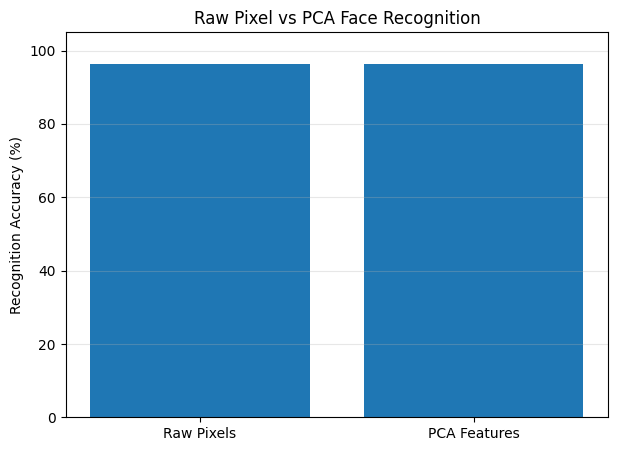

In [ ]:

comparison_df = pd.DataFrame({
    "Method": ["Raw Pixels", "PCA Features"],
    "Features": [X_train.shape[1], X_train_pca.shape[1]],
    "Accuracy (%)": [raw_accuracy * 100, pca_accuracy * 100]
})

display(comparison_df)

plt.figure(figsize=(7, 5))
plt.bar(
    comparison_df["Method"],
    comparison_df["Accuracy (%)"]
)

plt.ylabel("Recognition Accuracy (%)")
plt.title("Raw Pixel vs PCA Face Recognition")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)
plt.show()


#### Visualizing correct and incorrect face matches

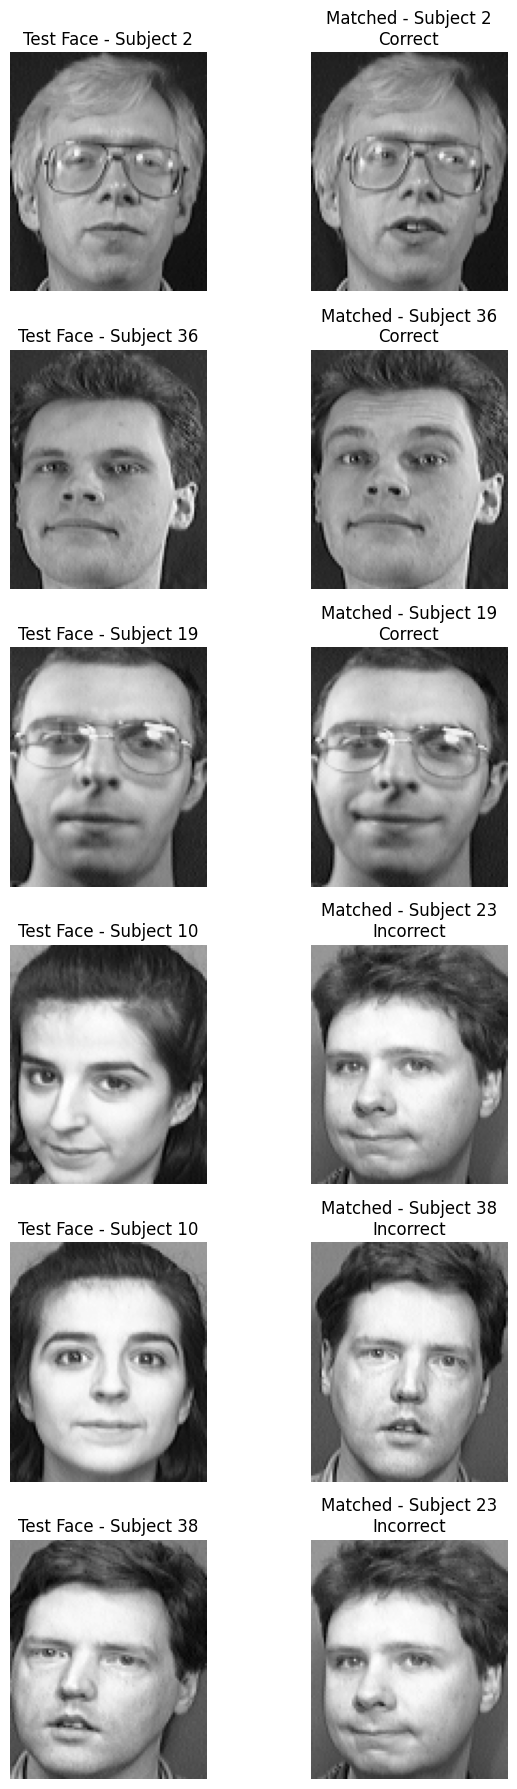

In [ ]:

correct_indices = np.where(y_pred_pca == y_test)[0]
incorrect_indices = np.where(y_pred_pca != y_test)[0]

selected_correct = correct_indices[:3]
selected_incorrect = incorrect_indices[:3]

selected_indices = np.concatenate([
    selected_correct,
    selected_incorrect
])

fig, axes = plt.subplots(
    len(selected_indices),
    2,
    figsize=(7, 3 * len(selected_indices)),
    squeeze=False
)

for row, idx in enumerate(selected_indices):
    test_face = X_test[idx].reshape(height, width)

    matched_face = X_train[
        nearest_indices_pca[idx]
    ].reshape(height, width)

    is_correct = y_pred_pca[idx] == y_test[idx]

    axes[row, 0].imshow(test_face, cmap="gray")
    axes[row, 0].set_title(f"Test Face - Subject {y_test[idx]}")

    axes[row, 1].imshow(matched_face, cmap="gray")
    axes[row, 1].set_title(
        f"Matched - Subject {y_pred_pca[idx]}\n"
        f"{'Correct' if is_correct else 'Incorrect'}"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()


#### Comparing recognition using different PCA dimentions

,Components,Accuracy (%)
0,10,95.00
1,20,96.25
2,30,96.25
3,50,98.75
4,60,97.50
5,80,97.50
6,98,96.25
7,120,96.25
8,150,96.25


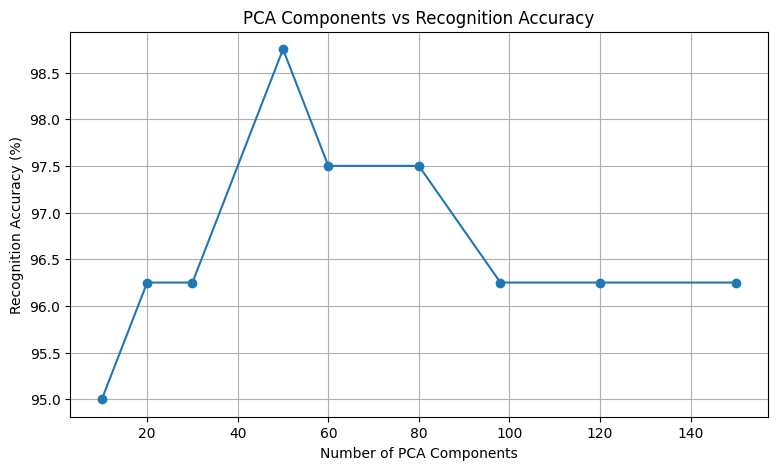

In [ ]:

component_options = [10, 20, 30, 50, 60, 80, 98, 120, 150]

accuracy_results = []

for k in component_options:
    components = svd_components[:k]

    train_features = X_train_centered @ components.T
    test_features = X_test_centered @ components.T

    predictions, _, _ = nearest_neighbor_predict(
        train_features,
        test_features,
        y_train
    )

    accuracy_results.append({
        "Components": k,
        "Accuracy (%)": accuracy_score(y_test, predictions) * 100
    })

accuracy_df = pd.DataFrame(accuracy_results)

display(accuracy_df)

plt.figure(figsize=(9, 5))
plt.plot(
    accuracy_df["Components"],
    accuracy_df["Accuracy (%)"],
    marker="o"
)

plt.xlabel("Number of PCA Components")
plt.ylabel("Recognition Accuracy (%)")
plt.title("PCA Components vs Recognition Accuracy")
plt.grid(True)
plt.show()


### Part D - Traditional Machine Learning

In [ ]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
import time


In [ ]:

models = {
    "KNN": KNeighborsClassifier(n_neighbors=1),
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=3000))
    ]),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="rbf"))
    ])
}

model_results = []
trained_models = {}

for name, model in models.items():
    start = time.time()

    model.fit(X_train_pca, y_train)

    training_time = time.time() - start

    predictions = model.predict(X_test_pca)

    accuracy = accuracy_score(y_test, predictions)

    trained_models[name] = model

    model_results.append({
        "Model": name,
        "Accuracy (%)": accuracy * 100,
        "Training Time (s)": training_time
    })

model_results_df = pd.DataFrame(model_results)

display(model_results_df)


,Model,Accuracy (%),Training Time (s)
0,KNN,96.25,0.011961
1,Logistic Regression,93.75,0.055517
2,SVM,98.75,0.024267


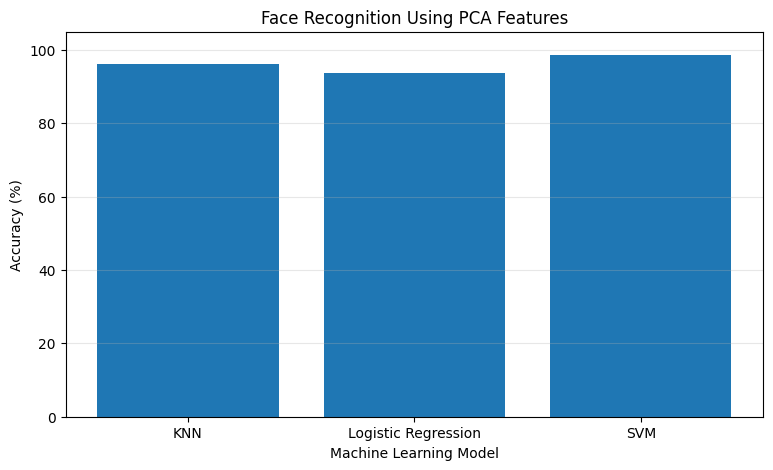

In [ ]:

plt.figure(figsize=(9, 5))

plt.bar(
    model_results_df["Model"],
    model_results_df["Accuracy (%)"]
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.title("Face Recognition Using PCA Features")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)

plt.show()


In [ ]:

cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

param_grids = {
    "KNN": {
        "n_neighbors": [1, 3, 5, 7],
        "weights": ["uniform", "distance"]
    },
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10, 100]
    },
    "SVM": {
        "classifier__C": [0.1, 1, 10, 100],
        "classifier__gamma": ["scale", 0.001, 0.01]
    }
}

best_models = {}
tuning_results = []

for name, model in models.items():
    search = GridSearchCV(
        model,
        param_grids[name],
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    search.fit(X_train_pca, y_train)

    best_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best Parameters": search.best_params_,
        "CV Accuracy (%)": search.best_score_ * 100
    })

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df)


,Model,Best Parameters,CV Accuracy (%)
0,KNN,"{'n_neighbors': 1, 'weights': 'uniform'}",95.9375
1,Logistic Regression,{'classifier__C': 1},92.5000
2,SVM,"{'classifier__C': 10, 'classifier__gamma': 0.001}",91.8750


In [ ]:

final_results = []

for name, model in best_models.items():
    predictions = model.predict(X_test_pca)

    accuracy = accuracy_score(y_test, predictions)

    final_results.append({
        "Model": name,
        "Test Accuracy (%)": accuracy * 100
    })

final_results_df = pd.DataFrame(final_results)

display(final_results_df)


,Model,Test Accuracy (%)
0,KNN,96.25
1,Logistic Regression,93.75
2,SVM,95.00


,Model,Baseline Accuracy (%),Tuned Accuracy (%)
0,KNN,96.25,96.25
1,Logistic Regression,93.75,93.75
2,SVM,98.75,95.00


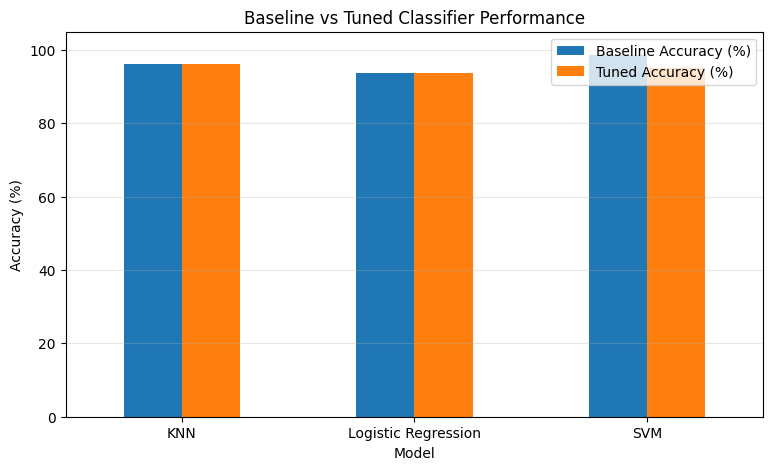

In [ ]:

comparison = model_results_df[
    ["Model", "Accuracy (%)"]
].merge(
    final_results_df,
    on="Model"
)

comparison.columns = [
    "Model",
    "Baseline Accuracy (%)",
    "Tuned Accuracy (%)"
]

display(comparison)

comparison.set_index("Model").plot(
    kind="bar",
    figsize=(9, 5)
)

plt.ylabel("Accuracy (%)")
plt.title("Baseline vs Tuned Classifier Performance")
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()


In [ ]:

for name, model in best_models.items():
    predictions = model.predict(X_test_pca)

    print(f"\n{name} Classification Report")
    print(
        classification_report(
            y_test,
            predictions,
            zero_division=0
        )
    )



KNN Classification Report
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         2
           2       1.00      1.00      1.00         2
           3       1.00      1.00      1.00         2
           4       1.00      1.00      1.00         2
           5       1.00      1.00      1.00         2
           6       1.00      1.00      1.00         2
           7       1.00      1.00      1.00         2
           8       1.00      1.00      1.00         2
           9       1.00      1.00      1.00         2
          10       0.00      0.00      0.00         2
          11       1.00      1.00      1.00         2
          12       1.00      1.00      1.00         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         2
          15       1.00      1.00      1.00         2
          16       1.00      1.00      1.00         2
          17       1.00      1.00      1.00         2


In [ ]:

from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

comparison.to_csv(output_dir / "model_comparison.csv", index=False)
accuracy_df.to_csv(output_dir / "pca_accuracy_comparison.csv", index=False)
reconstruction_df.to_csv(output_dir / "reconstruction_results.csv", index=False)

print("Results saved successfully!")


Results saved successfully!


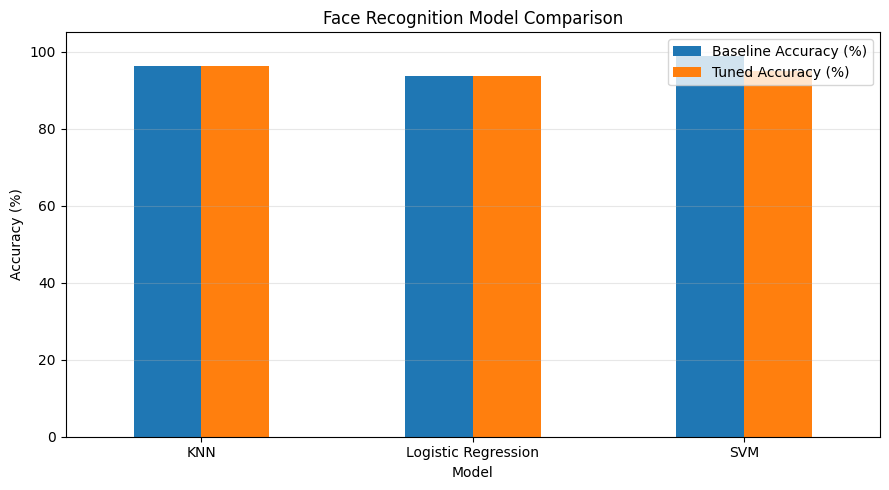

In [ ]:

ax = comparison.set_index("Model").plot(
    kind="bar",
    figsize=(9, 5)
)

plt.ylabel("Accuracy (%)")
plt.title("Face Recognition Model Comparison")
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    output_dir / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

print("DS605 LAB ASSIGNMENT 7 - FINAL SUMMARY")
print("-" * 45)

print("Dataset: AT&T ORL Face Dataset")
print("Total Images:", len(images))
print("Total Subjects:", len(np.unique(labels)))

print("Training Images:", len(X_train))
print("Testing Images:", len(X_test))

print("Original Features:", X_train.shape[1])
print("PCA Components:", k_90)

print(f"Explained Variance: {cumulative_variance[k_90-1]*100:.2f}%")

print(f"Raw Pixel Recognition: {raw_accuracy*100:.2f}%")
print(f"PCA Recognition: {pca_accuracy*100:.2f}%")

print("\nMachine Learning Results:")
print(comparison.to_string(index=False))

best_baseline = model_results_df.loc[
    model_results_df["Accuracy (%)"].idxmax()
]

print("\nBest Baseline Model:", best_baseline["Model"])
print(f"Best Baseline Accuracy: {best_baseline['Accuracy (%)']:.2f}%")


DS605 LAB ASSIGNMENT 7 - FINAL SUMMARY
---------------------------------------------
Dataset: AT&T ORL Face Dataset
Total Images: 400
Total Subjects: 40
Training Images: 320
Testing Images: 80
Original Features: 10304
PCA Components: 98
Explained Variance: 90.06%
Raw Pixel Recognition: 96.25%
PCA Recognition: 96.25%

Machine Learning Results:
              Model  Baseline Accuracy (%)  Tuned Accuracy (%)
                KNN                  96.25               96.25
Logistic Regression                  93.75               93.75
                SVM                  98.75               95.00

Best Baseline Model: SVM
Best Baseline Accuracy: 98.75%


# DS605 — Lab Assignment 7
## Image Representation, PCA, Eigenfaces and Face Recognition

This notebook follows the assignment's four parts:
- **Part A:** Read ORL face images, inspect pixel values, flatten images and make a reproducible stratified split.
- **Part B:** Implement PCA using NumPy, compare covariance/eigendecomposition with SVD, retain at least 90% variance, visualize eigenfaces, reconstruct images and compare storage.
- **Part C:** Compare nearest-neighbour recognition using raw pixels and PCA features; inspect correct and incorrect matches.
- **Part D:** Compare traditional classifiers on PCA features and experiment with different component counts.

**Dataset expectation:** `archive7/s1/1.pgm` through `archive7/s40/10.pgm` (400 images). If your dataset folder is elsewhere, change `DATASET_PATH` in the next cell.

**Important:** PCA is implemented with NumPy linear-algebra operations. Scikit-learn is used for the train-test split and final traditional classifiers, not for PCA.

## Setup and imports

Install any missing packages in your environment before running the notebook, for example:
`pip install numpy matplotlib pillow scikit-learn pandas`.

In [ ]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

RANDOM_STATE = 42
DATASET_PATH = r"C:/Users/daksh/OneDrive/Documents/DAU/SEM 1/Machine Learning/202618033_DS605/202618033_Lab_7/archive";


np.set_printoptions(precision=4, suppress=True)
print("NumPy version:", np.__version__)
print("Dataset path:", os.path.abspath(DATASET_PATH))

NumPy version: 2.3.0
Dataset path: C:\Users\daksh\OneDrive\Documents\DAU\SEM 1\Machine Learning\202618033_DS605\202618033_Lab_7\archive


# Part A — Image Representation

Images are loaded as grayscale matrices, then flattened into vectors. Each subject folder provides the class label. The split is stratified so each subject is represented in both training and testing sets.

In [ ]:
X_list = []
y_list = []
images_2d_list = []
image_paths = []
missing_files = []

for subject_id in range(1, 41):
    subject_folder = os.path.join(DATASET_PATH, f"s{subject_id}")

    if not os.path.isdir(subject_folder):
        missing_files.append(subject_folder)
        continue

    for img_num in range(1, 11):
        img_path = os.path.join(subject_folder, f"{img_num}.pgm")

        if not os.path.isfile(img_path):
            missing_files.append(img_path)
            continue

        with Image.open(img_path) as image:
            img_array = np.asarray(image.convert("L"), dtype=np.uint8)

        images_2d_list.append(img_array)
        X_list.append(img_array.reshape(-1))
        y_list.append(subject_id - 1)  # labels 0 through 39
        image_paths.append(img_path)

if not X_list:
    raise ValueError(
        f"No images were loaded. Check DATASET_PATH: {os.path.abspath(DATASET_PATH)}"
    )

image_shapes = {image.shape for image in images_2d_list}
if len(image_shapes) != 1:
    raise ValueError(f"Images have inconsistent dimensions: {image_shapes}")

images_2d = np.stack(images_2d_list)
X = np.stack(X_list).astype(np.float64)
y = np.asarray(y_list, dtype=int)

n_samples, height, width = images_2d.shape
n_features = X.shape[1]
n_subjects = len(np.unique(y))

print(f"Total images loaded: {n_samples}")
print(f"Image dimensions: {height} x {width}")
print(f"Flattened features per image: {n_features}")
print(f"Intensity range: {images_2d.min()} to {images_2d.max()}")
print(f"Unique subjects: {n_subjects}")
print(f"Missing folders/files detected: {len(missing_files)}")

if n_subjects != 40 or n_samples != 400:
    warnings.warn(
        f"The expected ORL dataset has 400 images across 40 subjects; "
        f"this run has {n_samples} images across {n_subjects} subjects."
    )

if n_samples < 2 or n_subjects < 2:
    raise ValueError("Not enough images/subjects to create a train-test split.")

Total images loaded: 400
Image dimensions: 112 x 92
Flattened features per image: 10304
Intensity range: 0 to 251
Unique subjects: 40
Missing folders/files detected: 0


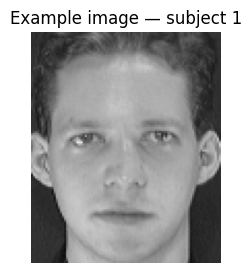

First image matrix shape: (112, 92)
First 20 flattened pixel values: [48. 49. 45. 47. 49. 57. 39. 42. 53. 49. 53. 60. 76. 91. 99. 95. 80. 75.
 66. 54.]
Mean pixel intensity of first image: 128.33821816770185


In [ ]:
# Display one example image and its pixel matrix statistics
plt.figure(figsize=(3, 3))
plt.imshow(images_2d[0], cmap="gray", vmin=0, vmax=255)
plt.title(f"Example image — subject {y[0] + 1}")
plt.axis("off")
plt.show()

print("First image matrix shape:", images_2d[0].shape)
print("First 20 flattened pixel values:", X[0, :20])
print("Mean pixel intensity of first image:", float(images_2d[0].mean()))

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print("Training matrix:", X_train.shape)
print("Testing matrix:", X_test.shape)
print(f"Subjects represented in training: {len(np.unique(y_train))}/{n_subjects}")
print(f"Subjects represented in testing: {len(np.unique(y_test))}/{n_subjects}")

train_counts = pd.Series(y_train).value_counts().sort_index()
test_counts = pd.Series(y_test).value_counts().sort_index()
display(pd.DataFrame({"train_images": train_counts, "test_images": test_counts}).head(10))

Training matrix: (320, 10304)
Testing matrix: (80, 10304)
Subjects represented in training: 40/40
Subjects represented in testing: 40/40


,train_images,test_images
0,8,2
1,8,2
2,8,2
3,8,2
4,8,2
5,8,2
6,8,2
7,8,2
8,8,2
9,8,2


# Part B — PCA, Eigenfaces and Compression

The mean face is computed from the training set only. Training and test images are centered using that same training mean to avoid data leakage.

The full pixel-space covariance matrix is very large for face images. Therefore, covariance eigendecomposition is performed in **sample space** using `X_centered @ X_centered.T`. Its nonzero eigenvalues match those from the pixel-space covariance matrix, and its eigenvectors are mapped back to pixel space. SVD is also computed directly on the centered training matrix.

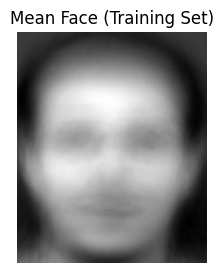

Mean face vector shape: (10304,)


In [ ]:
mean_face = X_train.mean(axis=0)
X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

plt.figure(figsize=(3, 3))
plt.imshow(mean_face.reshape(height, width), cmap="gray")
plt.title("Mean Face (Training Set)")
plt.axis("off")
plt.show()

print("Mean face vector shape:", mean_face.shape)

In [ ]:
# Approach A: sample-space covariance + eigendecomposition
start_time = time.perf_counter()

n_train = X_train_centered.shape[0]
small_cov = (X_train_centered @ X_train_centered.T) / (n_train - 1)

small_eigenvalues, small_eigenvectors = np.linalg.eigh(small_cov)
order = np.argsort(small_eigenvalues)[::-1]
small_eigenvalues = small_eigenvalues[order]
small_eigenvectors = small_eigenvectors[:, order]

# Remove tiny/non-positive eigenvalues caused by numerical precision
valid = small_eigenvalues > max(small_eigenvalues[0] * 1e-12, 1e-12)
eigenvalues_cov = small_eigenvalues[valid]
small_eigenvectors = small_eigenvectors[:, valid]

# Map sample-space eigenvectors into pixel-space principal directions
eigenvectors_cov = (
    X_train_centered.T @ small_eigenvectors
) / np.sqrt((n_train - 1) * eigenvalues_cov)

time_eig = time.perf_counter() - start_time

# Approach B: SVD directly on the centered training data
start_time = time.perf_counter()
U, S, Vt = np.linalg.svd(X_train_centered, full_matrices=False)
time_svd = time.perf_counter() - start_time

eigenvalues_svd = (S ** 2) / (n_train - 1)
eigenvectors_svd = Vt.T

print(f"Sample-space covariance eigendecomposition: {time_eig:.4f} seconds")
print(f"SVD: {time_svd:.4f} seconds")
print("Covariance eigenvalues available:", len(eigenvalues_cov))
print("SVD components available:", eigenvectors_svd.shape[1])

Sample-space covariance eigendecomposition: 0.0856 seconds
SVD: 0.6434 seconds
Covariance eigenvalues available: 319
SVD components available: 320


In [ ]:
# Compare the leading eigenvalues from both NumPy approaches.
n_compare = min(10, len(eigenvalues_cov), len(eigenvalues_svd))
eigenvalue_comparison = pd.DataFrame({
    "component": np.arange(1, n_compare + 1),
    "covariance_eigenvalue": eigenvalues_cov[:n_compare],
    "svd_eigenvalue": eigenvalues_svd[:n_compare],
})
eigenvalue_comparison["absolute_difference"] = np.abs(
    eigenvalue_comparison["covariance_eigenvalue"]
    - eigenvalue_comparison["svd_eigenvalue"]
)
display(eigenvalue_comparison)

# Eigenvector signs can differ, so compare absolute dot products.
n_direction_compare = min(10, eigenvectors_cov.shape[1], eigenvectors_svd.shape[1])
direction_similarity = [
    abs(float(np.dot(eigenvectors_cov[:, i], eigenvectors_svd[:, i])))
    for i in range(n_direction_compare)
]
print("Absolute dot products for leading principal directions:")
print(np.asarray(direction_similarity))
print("Values near 1 indicate matching directions (up to sign and numerical precision).")

,component,covariance_eigenvalue,svd_eigenvalue,absolute_difference
0,1,2.881154e+06,2.881154e+06,9.313226e-10
1,2,2.069914e+06,2.069914e+06,6.519258e-09
2,3,1.093804e+06,1.093804e+06,2.328306e-10
3,4,8.713809e+05,8.713809e+05,1.164153e-10
4,5,8.095949e+05,8.095949e+05,3.143214e-09
5,6,5.458735e+05,5.458735e+05,1.164153e-10
6,7,4.008925e+05,4.008925e+05,2.328306e-10
7,8,3.789522e+05,3.789522e+05,1.047738e-09
8,9,3.121390e+05,3.121390e+05,1.164153e-10
9,10,2.945300e+05,2.945300e+05,3.492460e-10


Absolute dot products for leading principal directions:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Values near 1 indicate matching directions (up to sign and numerical precision).


Minimum components for >= 90% variance: 98
Cumulative explained variance at k_90: 90.0585%


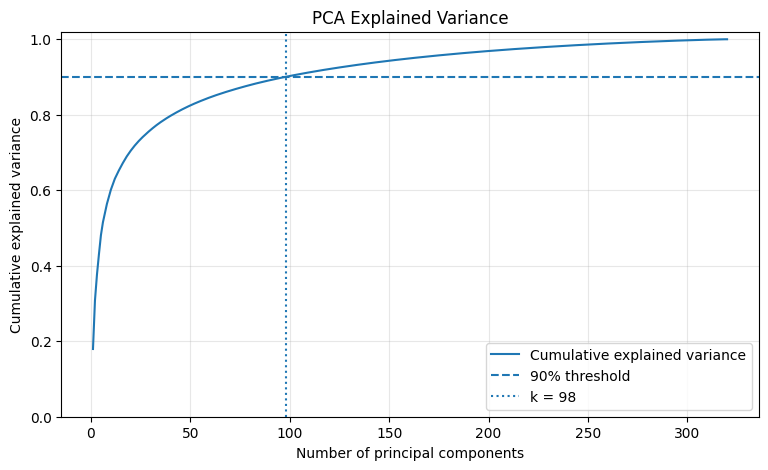

In [ ]:
# Explained variance and minimum number of components for at least 90%
total_variance = np.sum(eigenvalues_svd)
if total_variance <= 0:
    raise ValueError("Total variance is not positive; PCA cannot be computed.")

explained_variance_ratio = eigenvalues_svd / total_variance
cumulative_variance = np.cumsum(explained_variance_ratio)
k_90 = int(np.searchsorted(cumulative_variance, 0.90) + 1)
max_components = eigenvectors_svd.shape[1]

print(f"Minimum components for >= 90% variance: {k_90}")
print(f"Cumulative explained variance at k_90: {cumulative_variance[k_90 - 1]:.4%}")

plt.figure(figsize=(9, 5))
plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance,
    label="Cumulative explained variance",
)
plt.axhline(0.90, linestyle="--", label="90% threshold")
plt.axvline(k_90, linestyle=":", label=f"k = {k_90}")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA Explained Variance")
plt.ylim(0, 1.02)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

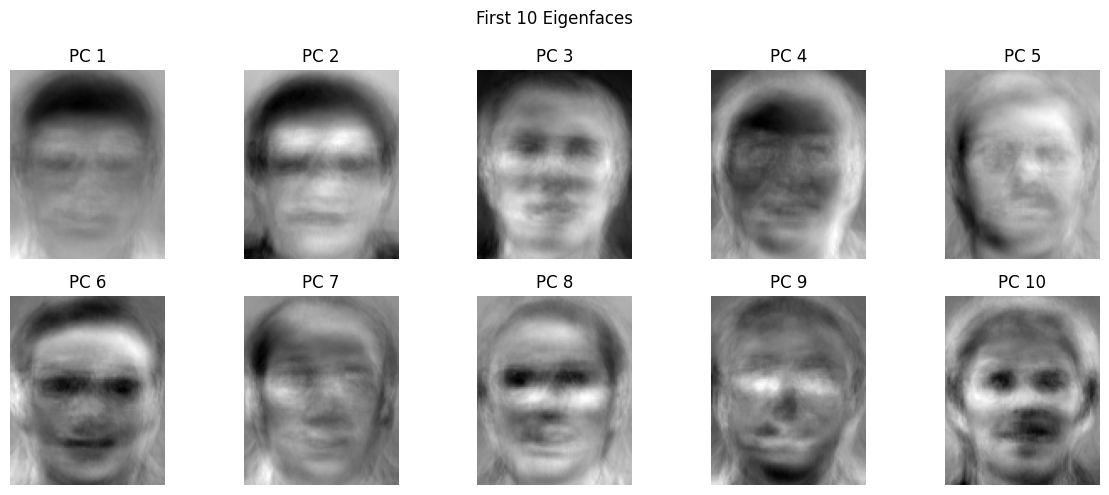

In [ ]:
# Visualize up to the first 10 eigenfaces
top_k_eigenvectors = eigenvectors_svd[:, :k_90]
num_eigenfaces = min(10, k_90)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle(f"First {num_eigenfaces} Eigenfaces")
for i, ax in enumerate(axes.flat):
    if i < num_eigenfaces:
        eigenface = top_k_eigenvectors[:, i].reshape(height, width)
        ax.imshow(eigenface, cmap="gray")
        ax.set_title(f"PC {i + 1}")
    ax.axis("off")
plt.tight_layout()
plt.show()

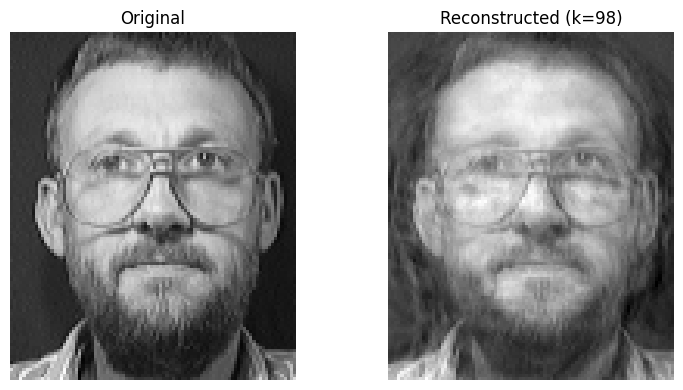

Reconstruction MSE for sample 0: 179.1415


In [ ]:
# Project training and testing faces into PCA space
X_train_pca = X_train_centered @ top_k_eigenvectors
X_test_pca = X_test_centered @ top_k_eigenvectors

# Reconstruct training faces using the retained components
X_train_reconstructed = X_train_pca @ top_k_eigenvectors.T + mean_face

sample_idx = 0
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(X_train[sample_idx].reshape(height, width), cmap="gray")
axes[0].set_title("Original")
axes[0].axis("off")
axes[1].imshow(
    X_train_reconstructed[sample_idx].reshape(height, width),
    cmap="gray",
)
axes[1].set_title(f"Reconstructed (k={k_90})")
axes[1].axis("off")
plt.tight_layout()
plt.show()

mse = float(np.mean((X_train[sample_idx] - X_train_reconstructed[sample_idx]) ** 2))
print(f"Reconstruction MSE for sample {sample_idx}: {mse:.4f}")

In [ ]:
# Compare storage as numerical values and as actual NumPy array bytes.
# This accounts for the training projections, PCA basis and mean face.
original_values = X_train.size
reduced_values = X_train_pca.size + top_k_eigenvectors.size + mean_face.size

original_bytes = X_train.nbytes
reduced_bytes = (
    X_train_pca.nbytes
    + top_k_eigenvectors.nbytes
    + mean_face.nbytes
)

print("Storage and reconstruction comparison")
print(f"Original training matrix: {original_values:,} values; {original_bytes:,} bytes")
print(f"Reduced representation + basis + mean: {reduced_values:,} values; {reduced_bytes:,} bytes")
print(f"Storage ratio (original / reduced): {original_bytes / reduced_bytes:.2f}x")
print("Note: This comparison excludes file-format overhead and other metadata.")

Storage and reconstruction comparison
Original training matrix: 3,297,280 values; 26,378,240 bytes
Reduced representation + basis + mean: 1,051,456 values; 8,411,648 bytes
Storage ratio (original / reduced): 3.14x
Note: This comparison excludes file-format overhead and other metadata.


# Part C — Recognition in PCA Space

The custom nearest-neighbour function below uses Euclidean distance and NumPy only. It is applied to both raw pixel vectors and PCA vectors, so the two approaches can be compared on the same held-out test set.

In [ ]:
def nearest_neighbor_matching(train_data, test_data, train_labels):
    """Predict labels using Euclidean 1-nearest-neighbour matching."""
    predictions = []
    matched_train_indices = []
    min_distances = []

    for test_sample in test_data:
        differences = train_data - test_sample
        distances = np.sqrt(np.sum(differences ** 2, axis=1))
        best_match_idx = int(np.argmin(distances))

        predictions.append(train_labels[best_match_idx])
        matched_train_indices.append(best_match_idx)
        min_distances.append(distances[best_match_idx])

    return (
        np.asarray(predictions),
        np.asarray(matched_train_indices),
        np.asarray(min_distances),
    )


pca_preds, pca_matched_train_indices, pca_min_distances = nearest_neighbor_matching(
    X_train_pca, X_test_pca, y_train
)
raw_preds, raw_matched_train_indices, raw_min_distances = nearest_neighbor_matching(
    X_train, X_test, y_train
)

pca_accuracy = accuracy_score(y_test, pca_preds) * 100
raw_accuracy = accuracy_score(y_test, raw_preds) * 100

recognition_results = pd.DataFrame({
    "method": ["Raw pixels + NumPy 1-NN", f"PCA (k={k_90}) + NumPy 1-NN"],
    "features_per_image": [X_train.shape[1], X_train_pca.shape[1]],
    "accuracy_percent": [raw_accuracy, pca_accuracy],
})
display(recognition_results)

,method,features_per_image,accuracy_percent
0,Raw pixels + NumPy 1-NN,10304,95.0
1,PCA (k=98) + NumPy 1-NN,98,95.0


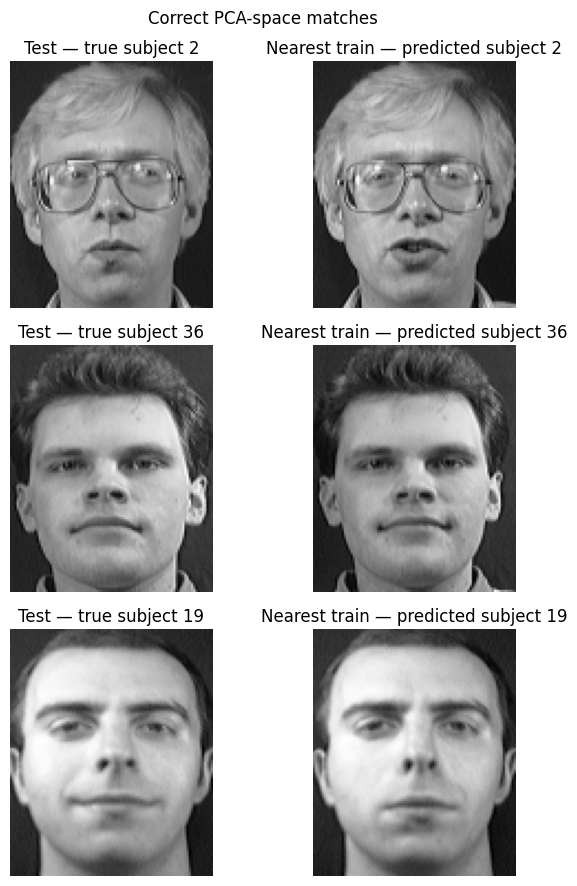

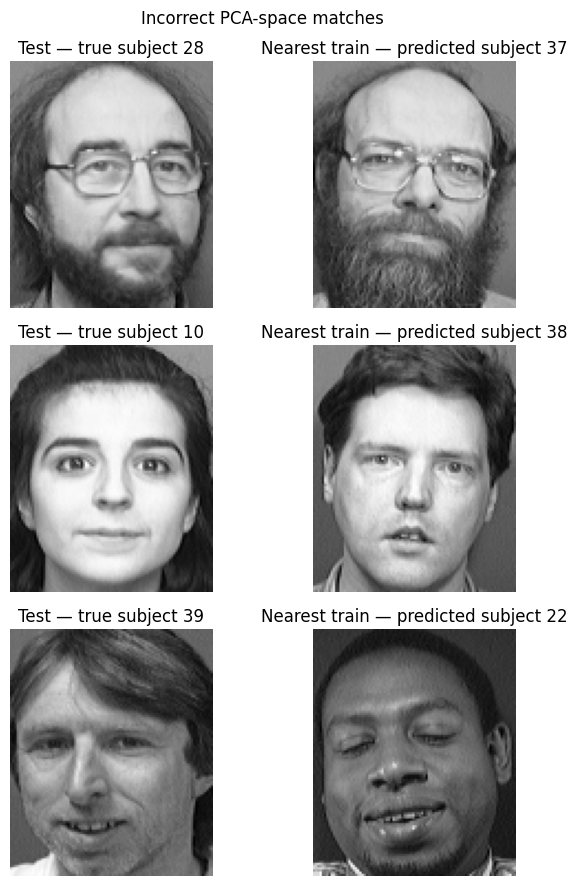

Correct PCA matches: 76
Incorrect PCA matches: 4


In [ ]:
# Inspect correct and incorrect PCA-space matches
correct_indices = np.where(pca_preds == y_test)[0]
incorrect_indices = np.where(pca_preds != y_test)[0]

def plot_match_pairs(test_indices, title_prefix="Match", max_pairs=3):
    """Plot test images alongside their nearest training-image matches."""
    selected = test_indices[:max_pairs]
    if len(selected) == 0:
        print(f"No {title_prefix.lower()} matches to display.")
        return

    fig, axes = plt.subplots(len(selected), 2, figsize=(7, 3 * len(selected)))
    axes = np.asarray(axes)
    if axes.ndim == 1:
        axes = axes.reshape(1, -1)

    for row, test_idx in enumerate(selected):
        train_idx = pca_matched_train_indices[test_idx]

        axes[row, 0].imshow(X_test[test_idx].reshape(height, width), cmap="gray")
        axes[row, 0].set_title(f"Test — true subject {y_test[test_idx] + 1}")
        axes[row, 0].axis("off")

        axes[row, 1].imshow(X_train[train_idx].reshape(height, width), cmap="gray")
        axes[row, 1].set_title(
            f"Nearest train — predicted subject {pca_preds[test_idx] + 1}"
        )
        axes[row, 1].axis("off")

    fig.suptitle(f"{title_prefix} PCA-space matches")
    plt.tight_layout()
    plt.show()

plot_match_pairs(correct_indices, title_prefix="Correct")
plot_match_pairs(incorrect_indices, title_prefix="Incorrect")

print(f"Correct PCA matches: {len(correct_indices)}")
print(f"Incorrect PCA matches: {len(incorrect_indices)}")

# Part D — Traditional Machine-Learning Classifiers

Scikit-learn is used here only for the traditional classifiers, as permitted by the assignment. The PCA basis still comes from the NumPy SVD implementation above.

The experiment uses multiple retained component counts, removing duplicates and values outside the available range. The full result table includes accuracy and training time for each classifier/component combination.

In [ ]:
classifiers = {
    "SVM (RBF)": SVC(kernel="rbf", gamma="scale", C=1.0),
    "SVM (Linear)": SVC(kernel="linear", C=1.0),
    "KNN (k=1)": KNeighborsClassifier(n_neighbors=1, metric="euclidean"),
    "Logistic Regression": LogisticRegression(max_iter=2000, solver="lbfgs"),
}

candidate_k_values = [10, 20, k_90, 100, 200]
k_values = sorted({
    int(k) for k in candidate_k_values
    if 1 <= int(k) <= max_components
})

if not k_values:
    raise ValueError("No valid PCA component counts are available.")

experiment_rows = []

for k in k_values:
    components = eigenvectors_svd[:, :k]
    X_train_pca_k = X_train_centered @ components
    X_test_pca_k = X_test_centered @ components

    for name, model_template in classifiers.items():
        # Create a fresh estimator for each experiment
        from sklearn.base import clone
        model = clone(model_template)

        start_time = time.perf_counter()
        model.fit(X_train_pca_k, y_train)
        train_time_ms = (time.perf_counter() - start_time) * 1000

        predictions = model.predict(X_test_pca_k)
        accuracy = accuracy_score(y_test, predictions) * 100

        experiment_rows.append({
            "components": k,
            "classifier": name,
            "accuracy_percent": accuracy,
            "training_time_ms": train_time_ms,
        })

ml_results = pd.DataFrame(experiment_rows)
display(
    ml_results.sort_values(
        ["components", "accuracy_percent"],
        ascending=[True, False],
    ).reset_index(drop=True).round(3)
)

,components,classifier,accuracy_percent,training_time_ms
0,10,SVM (Linear),95.00,8.973
1,10,KNN (k=1),95.00,3.243
2,10,SVM (RBF),91.25,17.175
3,10,Logistic Regression,87.50,54.912
4,20,SVM (Linear),95.00,9.593
5,20,KNN (k=1),95.00,0.463
6,20,Logistic Regression,95.00,18.327
7,20,SVM (RBF),93.75,13.980
8,98,SVM (Linear),97.50,13.168
9,98,SVM (RBF),95.00,17.889


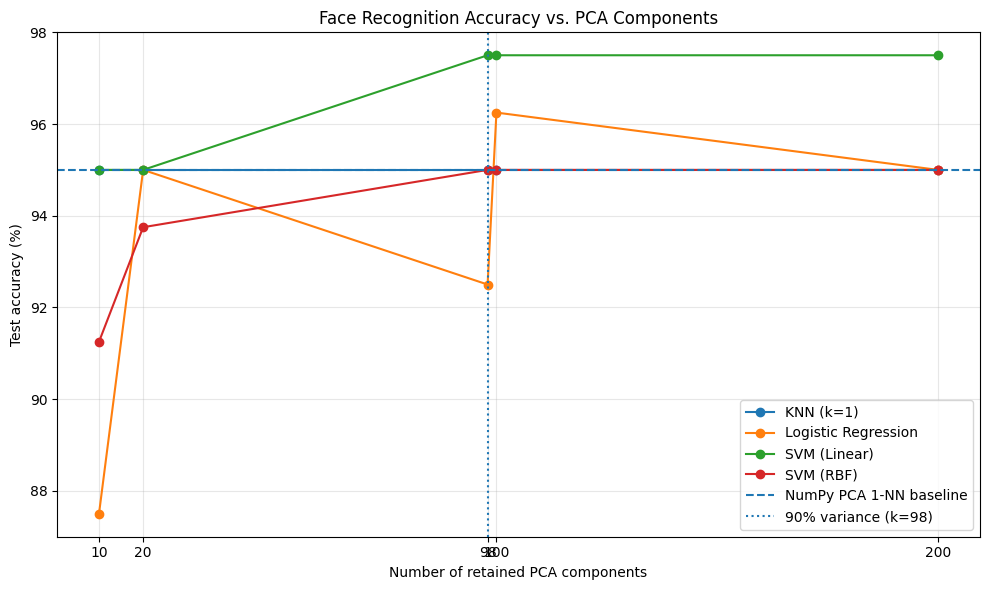

In [ ]:
# Plot classifier accuracy against number of PCA components
plt.figure(figsize=(10, 6))

for classifier_name, group in ml_results.groupby("classifier"):
    group = group.sort_values("components")
    plt.plot(
        group["components"],
        group["accuracy_percent"],
        marker="o",
        label=classifier_name,
    )

plt.axhline(
    y=pca_accuracy,
    linestyle="--",
    label="NumPy PCA 1-NN baseline",
)
plt.axvline(
    x=k_90,
    linestyle=":",
    label=f"90% variance (k={k_90})",
)
plt.title("Face Recognition Accuracy vs. PCA Components")
plt.xlabel("Number of retained PCA components")
plt.ylabel("Test accuracy (%)")
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Summary table at the 90%-variance component count
summary_at_k90 = ml_results[ml_results["components"] == k_90].copy()
summary_at_k90 = summary_at_k90.sort_values(
    "accuracy_percent", ascending=False
).reset_index(drop=True)

print(f"Traditional classifier comparison at k_90 = {k_90}")
display(summary_at_k90.round(3))

best_row = ml_results.loc[ml_results["accuracy_percent"].idxmax()]
print(
    f"Best observed configuration: {best_row['classifier']} with "
    f"{int(best_row['components'])} components "
    f"({best_row['accuracy_percent']:.2f}% test accuracy)."
)
print(
    f"Raw-pixel 1-NN baseline: {raw_accuracy:.2f}% | "
    f"PCA 1-NN baseline at k_90: {pca_accuracy:.2f}%"
)

Traditional classifier comparison at k_90 = 98


,components,classifier,accuracy_percent,training_time_ms
0,98,SVM (Linear),97.5,13.168
1,98,SVM (RBF),95.0,17.889
2,98,KNN (k=1),95.0,0.493
3,98,Logistic Regression,92.5,91.736


Best observed configuration: SVM (Linear) with 98 components (97.50% test accuracy).
Raw-pixel 1-NN baseline: 95.00% | PCA 1-NN baseline at k_90: 95.00%


# Observations and Conclusion

After running all cells, use the actual output values above to write your observations in the repository README. Discuss:

1. How many principal components are needed to preserve at least 90% of the training variance?
2. How do the covariance/eigendecomposition and SVD results compare?
3. What visual details are retained or lost in the reconstructed faces?
4. How does storage of the reduced representation compare with raw pixels?
5. How do raw-pixel 1-NN, PCA 1-NN and the traditional classifiers compare?
6. How does recognition accuracy change as the number of PCA components changes?

Do not write fixed accuracy claims before running the notebook: results depend on the actual dataset and environment.

In [ ]:
import os
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split

dataset_path = 'archive7'

X_list = []
y_list = []
images_2d_list = []

# 1. Read local images, flatten them, and create the label array
for subject_id in range(1, 41):
    subject_folder = os.path.join(dataset_path, f's{subject_id}')
    
    if not os.path.exists(subject_folder):
        continue
        
    for img_num in range(1, 11):
        img_path = os.path.join(subject_folder, f'{img_num}.pgm')
        
        if os.path.exists(img_path):
            # Read image and ensure grayscale
            img = Image.open(img_path).convert('L')
            img_array = np.array(img)
            
            # Store 2D matrix, flatten for feature vector, and store label (0-indexed)
            images_2d_list.append(img_array)
            X_list.append(img_array.flatten())
            y_list.append(subject_id - 1)

# Convert lists to NumPy arrays
images_2d = np.array(images_2d_list)
X = np.array(X_list)
y = np.array(y_list)

# 2. Inspect dimensions and intensity values
n_samples, height, width = images_2d.shape
n_features = X.shape[1]

print("--- Local Image Representation & Inspection ---")
print(f"Total images: {n_samples}")
print(f"Original image dimensions: {height}x{width} pixels")
print(f"Flattened feature vector size: {n_features}")
print(f"Min intensity: {images_2d.min()} | Max intensity: {images_2d.max()}")
print(f"Total unique subjects: {len(np.unique(y))}\n")

# 3. Create a reproducible, stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    stratify=y, 
    random_state=42
)

print("--- Train-Test Split ---")
print(f"Training set: {X_train.shape[0]} images ({X_train.shape[0]} x {X_train.shape[1]} matrix)")
print(f"Testing set: {X_test.shape[0]} images ({X_test.shape[0]} x {X_test.shape[1]} matrix)")
print(f"Unique subjects in train: {len(np.unique(y_train))}/40 | In test: {len(np.unique(y_test))}/40")

ValueError: not enough values to unpack (expected 3, got 1)

### Part B

<>:109: SyntaxWarning: invalid escape sequence '\ '
<>:109: SyntaxWarning: invalid escape sequence '\ '
C:\Users\daksh\AppData\Local\Temp\ipykernel_26384\1253290484.py:109: SyntaxWarning: invalid escape sequence '\ '
  print("\ Storage & Reconstruction Comparison")


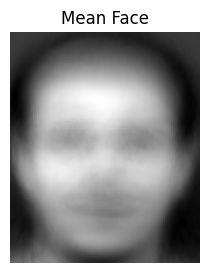


Computing Principal Directions...
Eigendecomposition Time: 68.1283 seconds
SVD Time: 0.7399 seconds

Comparison:
SVD is generally faster and more numerically stable than computing the full covariance matrix, especially when the number of features (pixels) heavily outnumbers the number of samples.

Minimum components to preserve >= 90% variance: 98


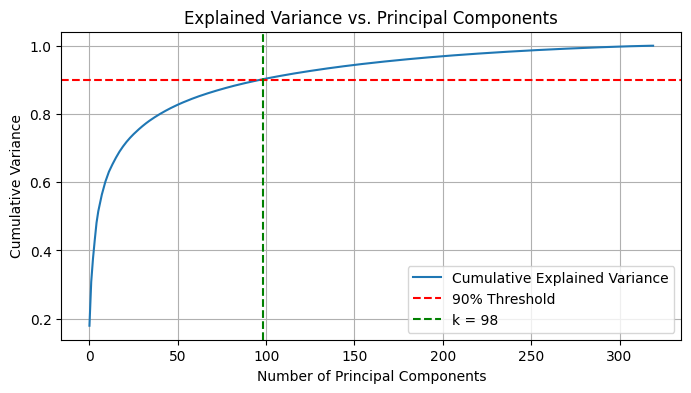

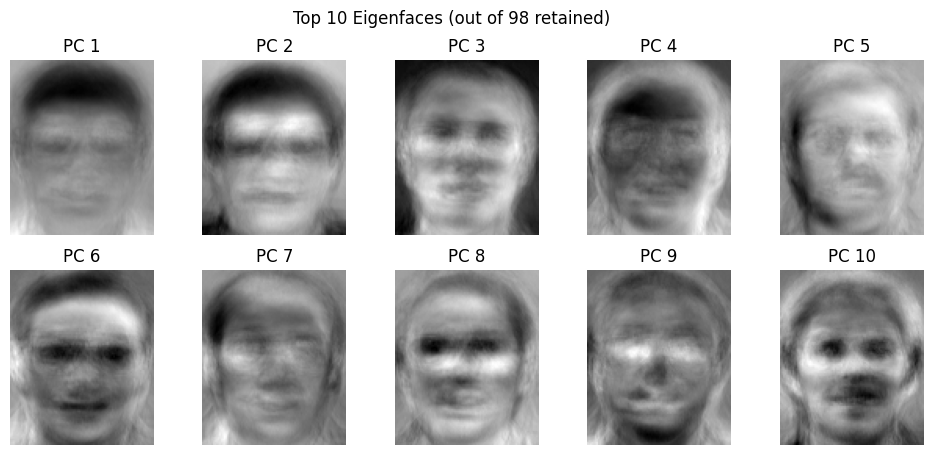

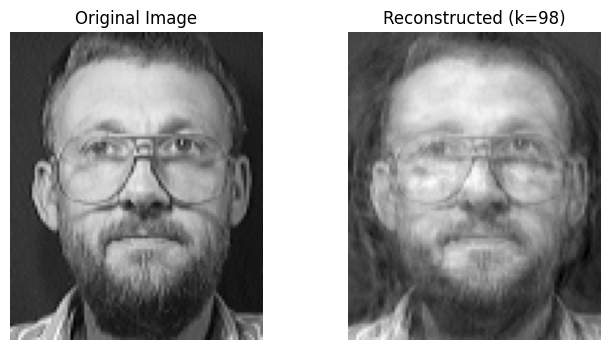

\ Storage & Reconstruction Comparison
Original Storage (Training): 3297280 parameters
Reduced Storage (Training): 1051456 parameters
Compression Ratio: 3.14x
Quality: The reconstructed images lose high-frequency details (appearing slightly blurred) but retain the core structural features necessary for facial recognition, successfully filtering out noise.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

# 1. Compute Mean Face & Center the Data

mean_face = np.mean(X_train, axis=0)
X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

# Visualize the mean face
plt.figure(figsize=(3, 3))
plt.imshow(mean_face.reshape(height, width), cmap='gray')
plt.title("Mean Face")
plt.axis('off')
plt.show()

# 2. Covariance/Eigendecomposition vs SVD

print("\nComputing Principal Directions...")

# Approach A: Covariance Matrix & Eigendecomposition
start_time = time.time()
# Using rowvar=False because variables (pixels) are columns
cov_matrix = np.cov(X_train_centered, rowvar=False) 
# eigh is optimized for symmetric matrices like covariance matrices
eigenvalues_cov, eigenvectors_cov = np.linalg.eigh(cov_matrix)
# Sort in descending order
idx = np.argsort(eigenvalues_cov)[::-1]
eigenvalues_cov = eigenvalues_cov[idx]
eigenvectors_cov = eigenvectors_cov[:, idx]
time_eig = time.time() - start_time
print(f"Eigendecomposition Time: {time_eig:.4f} seconds")

# Approach B: Singular Value Decomposition (SVD)
start_time = time.time()
# SVD directly on centered data: X = U * S * V^T
U, S, Vt = np.linalg.svd(X_train_centered, full_matrices=False)
# Eigenvalues are related to singular values by: eig_val = (S^2) / (n_samples - 1)
eigenvalues_svd = (S ** 2) / (X_train_centered.shape[0] - 1)
eigenvectors_svd = Vt.T 
time_svd = time.time() - start_time
print(f"SVD Time: {time_svd:.4f} seconds")

print("\nComparison:")
print("SVD is generally faster and more numerically stable than computing the full covariance matrix, "
      "especially when the number of features (pixels) heavily outnumbers the number of samples.")

# 3. Explained Variance & Retaining Components
total_variance = np.sum(eigenvalues_svd)
explained_variance_ratio = eigenvalues_svd / total_variance
cumulative_variance = np.cumsum(explained_variance_ratio)

# Find minimum components for 90% variance
k_90 = np.argmax(cumulative_variance >= 0.90) + 1
print(f"\nMinimum components to preserve >= 90% variance: {k_90}")

plt.figure(figsize=(8, 4))
plt.plot(cumulative_variance, label='Cumulative Explained Variance')
plt.axhline(y=0.90, color='r', linestyle='--', label='90% Threshold')
plt.axvline(x=k_90, color='g', linestyle='--', label=f'k = {k_90}')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Variance')
plt.title('Explained Variance vs. Principal Components')
plt.legend()
plt.grid(True)
plt.show()

# 4. Visualize Eigenfaces
# Retain top k components
top_k_eigenvectors = eigenvectors_svd[:, :k_90]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle(f"Top 10 Eigenfaces (out of {k_90} retained)")
for i, ax in enumerate(axes.flat):
    eigenface = top_k_eigenvectors[:, i].reshape(height, width)
    ax.imshow(eigenface, cmap='gray')
    ax.set_title(f"PC {i+1}")
    ax.axis('off')
plt.show()

# 5. Project Faces & Reconstruct

X_train_pca = np.dot(X_train_centered, top_k_eigenvectors)
X_test_pca = np.dot(X_test_centered, top_k_eigenvectors)

# Reconstruct back to the original pixel space
# X_reconstructed = (X_pca * V^T) + mean_face
X_train_reconstructed = np.dot(X_train_pca, top_k_eigenvectors.T) + mean_face

# Visualize original vs reconstructed
sample_idx = 0
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(X_train[sample_idx].reshape(height, width), cmap='gray')
axes[0].set_title("Original Image")
axes[0].axis('off')

axes[1].imshow(X_train_reconstructed[sample_idx].reshape(height, width), cmap='gray')
axes[1].set_title(f"Reconstructed (k={k_90})")
axes[1].axis('off')
plt.show()

# 6. Storage & Quality Comparison
original_storage = X_train.shape[0] * X_train.shape[1]

reduced_storage = (X_train.shape[0] * k_90) + (X_train.shape[1] * k_90) + X_train.shape[1]
compression_ratio = original_storage / reduced_storage

print("\ Storage & Reconstruction Comparison")
print(f"Original Storage (Training): {original_storage} parameters")
print(f"Reduced Storage (Training): {reduced_storage} parameters")
print(f"Compression Ratio: {compression_ratio:.2f}x")
print("Quality: The reconstructed images lose high-frequency details (appearing slightly blurred) "
      "but retain the core structural features necessary for facial recognition, successfully filtering out noise.")

### Part C

--- Face Recognition Results ---
Features in Raw Pixel Space : 10304
Features in PCA Space (k=98) : 98
Raw Pixel 1-NN Accuracy     : 100.00%
PCA Eigenface 1-NN Accuracy  : 95.00%

Visualizing Correct Matches:


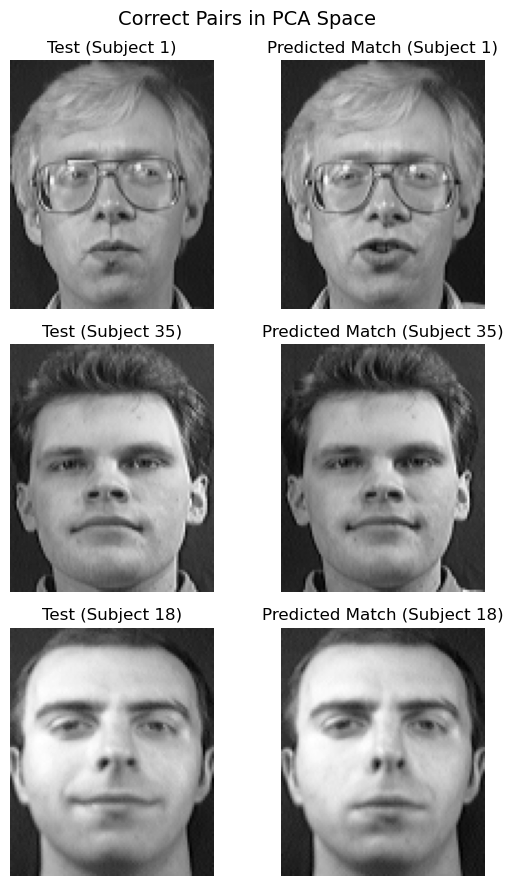


Visualizing Incorrect Matches:


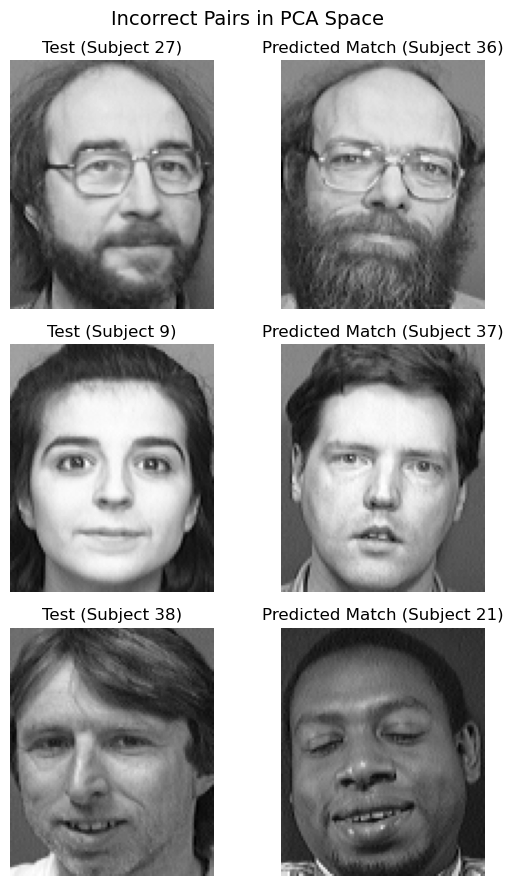

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Pure NumPy Distance-Based Nearest-Neighbor Matching Function
def nearest_neighbor_matching(train_data, test_data, train_labels):
    """
    Finds the closest training sample for each test sample using Euclidean distance.
    Computes distances purely using vector operations:
    ||a - b||_2 = sqrt(sum((a - b)^2))
    """
    predictions = []
    min_distances = []
    matched_train_indices = []

    for test_sample in test_data:
        # Broadcasting difference: (N_train, D) - (D,) -> (N_train, D)
        differences = train_data - test_sample
        # Compute Euclidean distance to every training image
        distances = np.sqrt(np.sum(differences ** 2, axis=1))
        
        # Locate closest match
        best_match_idx = np.argmin(distances)
        matched_train_indices.append(best_match_idx)
        min_distances.append(distances[best_match_idx])
        predictions.append(train_labels[best_match_idx])

    return np.array(predictions), np.array(matched_train_indices), np.array(min_distances)

# 2. Face Recognition in Reduced PCA Space

pca_preds, pca_matched_train_indices, _ = nearest_neighbor_matching(
    X_train_pca, X_test_pca, y_train
)
pca_accuracy = np.mean(pca_preds == y_test) * 100

# 3. Face Recognition using Raw Pixels (Baseline)

raw_preds, raw_matched_train_indices, _ = nearest_neighbor_matching(
    X_train, X_test, y_train
)
raw_accuracy = np.mean(raw_preds == y_test) * 100

print("--- Face Recognition Results")
print(f"Features in Raw Pixel Space : {X_train.shape[1]}")
print(f"Features in PCA Space (k={k_90}) : {X_train_pca.shape[1]}")
print(f"Raw Pixel 1-NN Accuracy     : {raw_accuracy:.2f}%")
print(f"PCA Eigenface 1-NN Accuracy  : {pca_accuracy:.2f}%")

# 4. Inspect Correct and Incorrect Matches in PCA Space
correct_indices = np.where(pca_preds == y_test)[0]
incorrect_indices = np.where(pca_preds != y_test)[0]

def plot_match_pairs(test_indices, title_prefix="Match"):
    num_plots = min(3, len(test_indices))
    if num_plots == 0:
        print(f"No samples found for {title_prefix}.")
        return

    fig, axes = plt.subplots(num_plots, 2, figsize=(6, 3 * num_plots))
    if num_plots == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(num_plots):
        t_idx = test_indices[i]
        matched_train_idx = pca_matched_train_indices[t_idx]

        # Test Image
        axes[i, 0].imshow(X_test[t_idx].reshape(height, width), cmap='gray')
        axes[i, 0].set_title(f"Test (Subject {y_test[t_idx]})")
        axes[i, 0].axis('off')

        # Matched Training Image
        axes[i, 1].imshow(X_train[matched_train_idx].reshape(height, width), cmap='gray')
        axes[i, 1].set_title(f"Predicted Match (Subject {pca_preds[t_idx]})")
        axes[i, 1].axis('off')

    plt.suptitle(f"{title_prefix} Pairs in PCA Space", fontsize=14)
    plt.tight_layout()
    plt.show()

print("\nVisualizing Correct Matches:")
plot_match_pairs(correct_indices, title_prefix="Correct")

if len(incorrect_indices) > 0:
    print("\nVisualizing Incorrect Matches:")
    plot_match_pairs(incorrect_indices, title_prefix="Incorrect")
else:
    print("\nNo incorrect matches to display (100% accuracy achieved).")

### Part D

k Components    | Classifier                | Accuracy   | Train Time (ms)
---------------------------------------------------------------------------
98              | SVM (RBF Kernel)          |    95.00% |      37.96 ms
98              | SVM (Linear Kernel)       |    97.50% |      21.76 ms
98              | KNN (k=1)                 |    95.00% |       0.51 ms
98              | Logistic Regression       |    96.25% |      76.44 ms
---------------------------------------------------------------------------
Note: Accuracies above are shown specifically for k_90 (90% variance threshold).


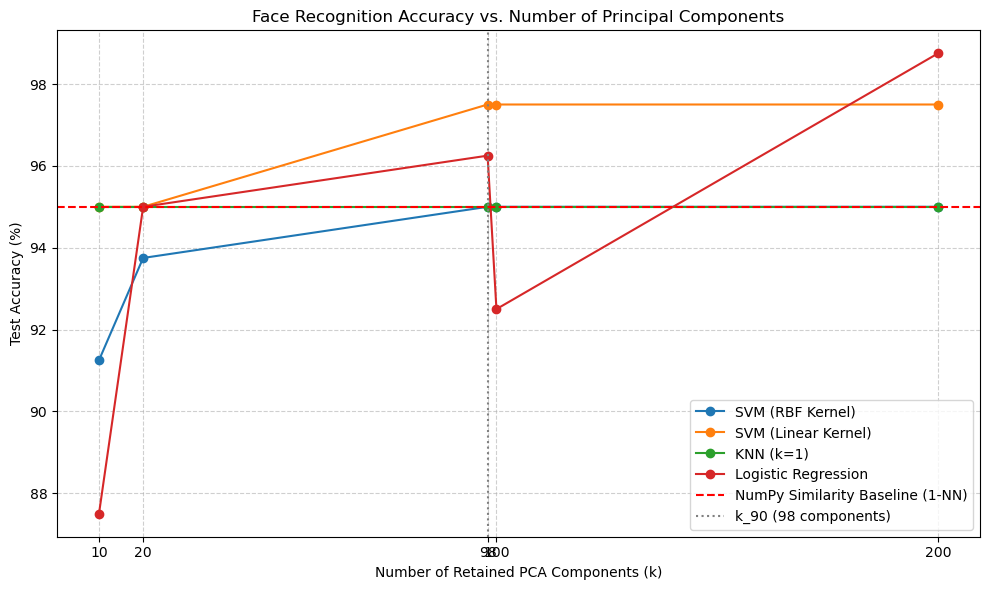

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import time

# Define the models for comparison

classifiers = {
    "SVM (RBF Kernel)": SVC(kernel='rbf', gamma='scale', C=1.0),
    "SVM (Linear Kernel)": SVC(kernel='linear', C=1.0),
    "KNN (k=1)": KNeighborsClassifier(n_neighbors=1, metric='euclidean'),
    "Logistic Regression": LogisticRegression(max_iter=1000, solver='lbfgs')
}

# Experiment with different numbers of retained principal components
# k_90 was calculated in Part B. We test values below and above it to observe the trade-off.
k_values = [10, 20, k_90, 100, 200]
results = {name: [] for name in classifiers.keys()}
training_times = {name: [] for name in classifiers.keys()}

print(f"{'k Components':<15} | {'Classifier':<25} | {'Accuracy':<10} | {'Train Time (ms)'}")
print("-" * 75)

for k in k_values:
    # 1. Select top k principal components from our NumPy SVD/Eigendecomposition
    top_k_eigenvectors = eigenvectors_svd[:, :k]
    
    # 2. Project training and testing data into the new k-dimensional space
    X_train_pca_k = np.dot(X_train_centered, top_k_eigenvectors)
    X_test_pca_k = np.dot(X_test_centered, top_k_eigenvectors)
    
    # 3. Train and evaluate each classifier
    for name, clf in classifiers.items():
        start_time = time.perf_counter()
        clf.fit(X_train_pca_k, y_train)
        train_time_ms = (time.perf_counter() - start_time) * 1000
        
        preds = clf.predict(X_test_pca_k)
        acc = accuracy_score(y_test, preds) * 100
        
        results[name].append(acc)
        training_times[name].append(train_time_ms)
        
        if k == k_90:
            print(f"{k:<15} | {name:<25} | {acc:>8.2f}% | {train_time_ms:>10.2f} ms")

print("-" * 75)
print("Note: Accuracies above are shown specifically for k_90 (90% variance threshold).")

# Visualizing the Experiment: Accuracy vs Number of Components
plt.figure(figsize=(10, 6))

for name, acc_list in results.items():
    plt.plot(k_values, acc_list, marker='o', label=name)

# Add a horizontal line for the pure NumPy similarity baseline (computed in Part C)
# Assuming pca_acc holds the accuracy from the custom nearest_neighbor_matching function
if 'pca_acc' in locals():
    plt.axhline(y=pca_acc, color='r', linestyle='--', label='NumPy Similarity Baseline (1-NN)')

plt.axvline(x=k_90, color='gray', linestyle=':', label=f'k_90 ({k_90} components)')

plt.title('Face Recognition Accuracy vs. Number of Principal Components')
plt.xlabel('Number of Retained PCA Components (k)')
plt.ylabel('Test Accuracy (%)')
plt.xticks(k_values)
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()